In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


In [2]:
import pandas as pd

raw = pd.read_csv("C://Users//MSI//Desktop//AI ENGINEER//ML ENGINEER//GOLD-PRICE-FORECASTING//gold_monthly_avg.csv",header=None
)

# Vrais noms des colonnes
columns = [
    "Date",
    "USD",
    "EUR",
    "JPY",
    "GBP",
    "CAD",
    "CHF",
    "INR",
    "CNY",
    "TRY",
    "SAR",
    "IDR",
    "AED",
    "THB",
    "VND",
    "EGP",
    "KRW",
    "RUB",
    "ZAR",
    "AUD"
]

# Extraire les données
df = raw.iloc[5:, 2:22].copy()

# Affecter les noms
df.columns = columns

# Reset index
df.reset_index(drop=True, inplace=True)

# Convertir Date
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convertir les prix
for col in columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Supprimer les lignes sans date
df = df.dropna(subset=["Date"])

print(df.head())
print(df.tail())

        Date     USD        EUR          JPY        GBP        CAD        CHF  \
1 1978-01-31  207.83  129.20810          NaN  104.62599        NaN        NaN   
2 1978-02-28  227.27  139.53296  44853.10621  113.32103  269.54823  378.77281   
3 1978-03-31  245.67  151.30799  49213.15041  122.54972  293.17263  410.58371   
4 1978-04-28  242.05  149.30073  49989.43254  118.79066  284.20489  407.26165   
5 1978-05-31  239.16  148.76416  51707.16895  115.43299  274.23889  410.50434   

   INR  CNY  TRY        SAR           IDR        AED         THB  VND  EGP  \
1  NaN  NaN  NaN        NaN           NaN        NaN         NaN  NaN  NaN   
2  NaN  NaN  NaN  754.08837  141796.36585  869.39601  4582.17775  NaN  NaN   
3  NaN  NaN  NaN  822.30530  153099.59140  939.09373  4949.49689  NaN  NaN   
4  NaN  NaN  NaN  810.13899  151068.54230  926.22479  4884.52856  NaN  NaN   
5  NaN  NaN  NaN  817.29641  149744.25491  919.93608  4842.57197  NaN  NaN   

            KRW  RUB        ZAR        AUD  

In [3]:
print(df.shape)
print(df.describe())
print(df.info())
print(df.columns)

(585, 20)
                                Date          USD          EUR            JPY  \
count                            585   585.000000   585.000000     584.000000   
mean   2002-05-30 22:23:59.999999872   892.513214   758.324821  114443.777332   
min              1978-01-31 00:00:00   207.830000   129.208100   28312.980370   
25%              1990-03-30 00:00:00   356.300000   307.319540   43169.258277   
50%              2002-05-31 00:00:00   438.350000   392.499950   79597.669785   
75%              2014-07-31 00:00:00  1282.280000  1078.370000  136890.625000   
max              2026-09-30 00:00:00  5019.530000  4245.110000  778287.980000   
std                              NaN   823.183792   718.286192  118454.289033   

               GBP          CAD          CHF            INR           CNY  \
count   585.000000   584.000000   584.000000     252.000000    512.000000   
mean    613.636023  1129.014635   973.787399  120779.426439   6475.584763   
min     104.625990   269.5482

In [4]:

print("\nMissing values:")
print(df.isna().sum())


Missing values:
Date      0
USD       0
EUR       0
JPY       1
GBP       0
CAD       1
CHF       1
INR     333
CNY      73
TRY      49
SAR       1
IDR       1
AED       1
THB       1
VND     132
EGP     120
KRW       1
RUB     169
ZAR       1
AUD       1
dtype: int64


In [5]:
print(df["Date"].head(10))
print(df["Date"].tail(10))

1    1978-01-31
2    1978-02-28
3    1978-03-31
4    1978-04-28
5    1978-05-31
6    1978-06-30
7    1978-07-31
8    1978-08-31
9    1978-09-29
10   1978-10-31
Name: Date, dtype: datetime64[ns]
576   2025-12-31
577   2026-01-30
578   2026-02-27
579   2026-03-31
580   2026-04-30
581   2026-05-29
582   2026-06-30
583   2026-07-31
584   2026-08-31
585   2026-09-30
Name: Date, dtype: datetime64[ns]


In [6]:
print("Première date :", df["Date"].iloc[0])
print("Dernière date :", df["Date"].iloc[-1])

Première date : 1978-01-31 00:00:00
Dernière date : 2026-09-30 00:00:00


In [7]:
# Vérifications temporelles
print("Période :", df["Date"].min(), "→", df["Date"].max())
print("Nombre de lignes :", len(df))

print("Dates dupliquées :", df["Date"].duplicated().sum())
print("Dates croissantes :", df["Date"].is_monotonic_increasing)

# Vérifier les valeurs manquantes de USD
print("Valeurs manquantes USD :", df["USD"].isna().sum())

# Statistiques du prix de l'or
print(df["USD"].describe())

Période : 1978-01-31 00:00:00 → 2026-09-30 00:00:00
Nombre de lignes : 585
Dates dupliquées : 0
Dates croissantes : True
Valeurs manquantes USD : 0
count     585.000000
mean      892.513214
std       823.183792
min       207.830000
25%       356.300000
50%       438.350000
75%      1282.280000
max      5019.530000
Name: USD, dtype: float64


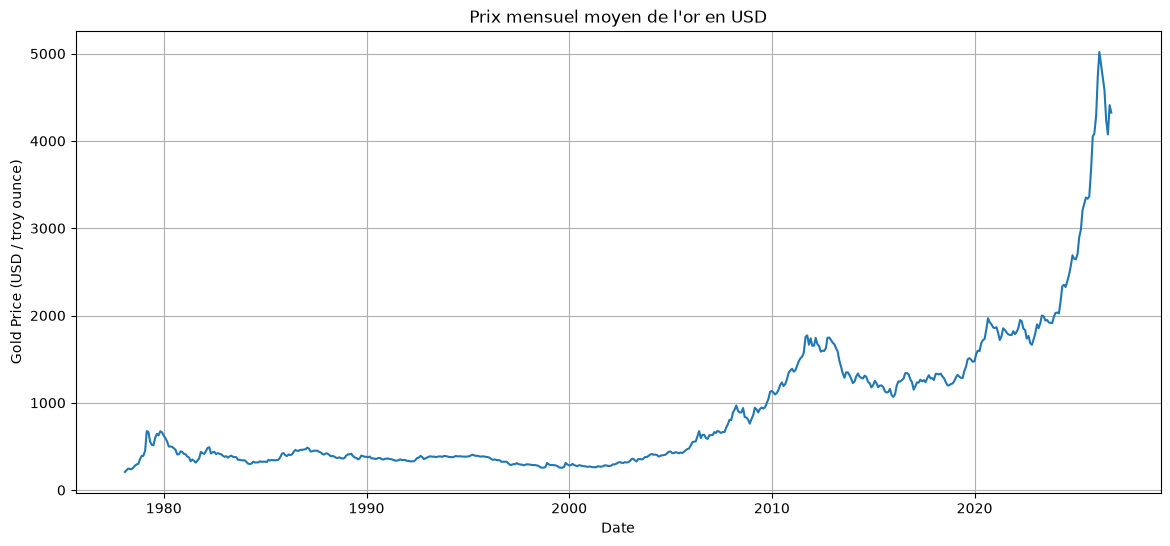

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["USD"])

plt.title("Prix mensuel moyen de l'or en USD")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD / troy ounce)")
plt.grid(True)

plt.show()

In [9]:
df["USD_diff"] = df["USD"].diff()

print(df[["Date", "USD", "USD_diff"]].head(10))

         Date     USD  USD_diff
1  1978-01-31  207.83       NaN
2  1978-02-28  227.27     19.44
3  1978-03-31  245.67     18.40
4  1978-04-28  242.05     -3.62
5  1978-05-31  239.16     -2.89
6  1978-06-30  257.62     18.46
7  1978-07-31  279.07     21.45
8  1978-08-31  294.74     15.67
9  1978-09-29  300.82      6.08
10 1978-10-31  355.11     54.29


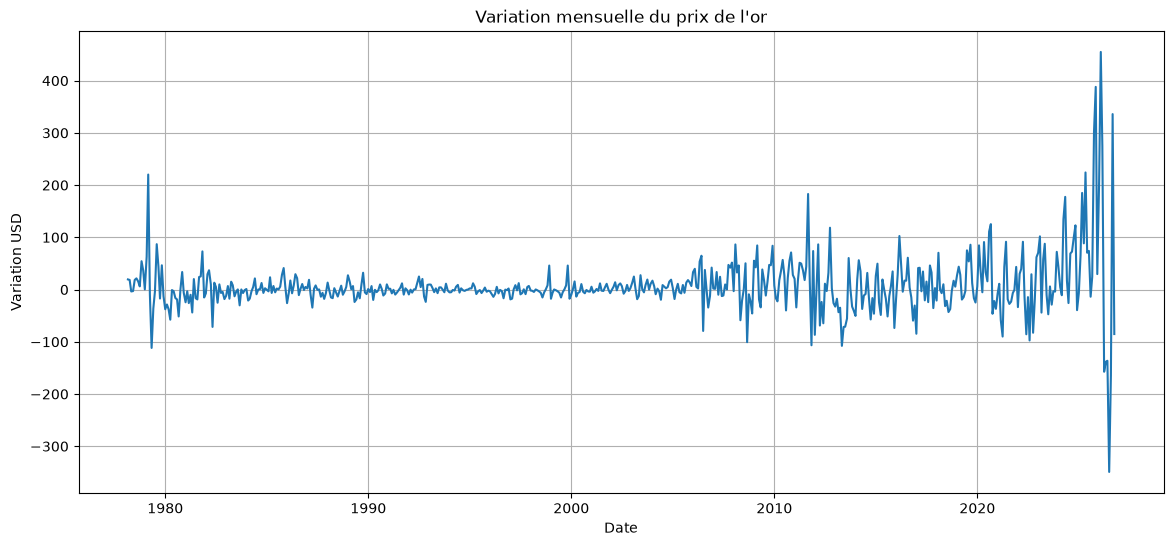

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["USD_diff"])

plt.title("Variation mensuelle du prix de l'or")
plt.xlabel("Date")
plt.ylabel("Variation USD")
plt.grid(True)

plt.show()

In [11]:
df["USD_return"] = df["USD"].pct_change()

print(df["USD_return"].describe())

count    584.000000
mean       0.006238
std        0.046705
min       -0.167949
25%       -0.017600
50%        0.000478
75%        0.026620
max        0.483937
Name: USD_return, dtype: float64


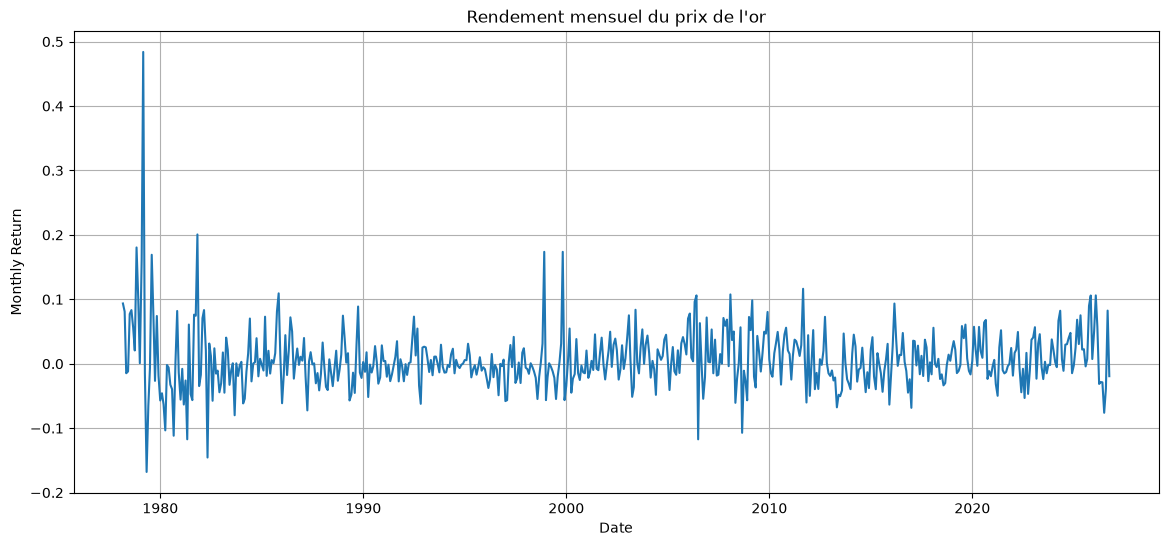

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["USD_return"])

plt.title("Rendement mensuel du prix de l'or")
plt.xlabel("Date")
plt.ylabel("Monthly Return")

plt.grid(True)

plt.show()

In [13]:
result_usd = adfuller(df["USD"])

print("ADF Statistic :", result_usd[0])
print("p-value :", result_usd[1])
print("Critical Values :")

for key, value in result_usd[4].items():
    print(f"   {key} : {value}")

ADF Statistic : 1.521257208082571
p-value : 0.9976010129332586
Critical Values :
   1% : -3.4418139386911513
   5% : -2.866597262008035
   10% : -2.5694633721967906


C:\Users\MSI\AppData\Local\Temp\ipykernel_8644\2526501529.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_usd = adfuller(df["USD"])


In [14]:
result_diff = adfuller(df["USD_diff"].dropna())

print("ADF Statistic :", result_diff[0])
print("p-value :", result_diff[1])
print("Critical Values :")

for key, value in result_diff[4].items():
    print(f"   {key} : {value}")

ADF Statistic : -4.741554862414952
p-value : 7.025974033364909e-05
Critical Values :
   1% : -3.4418139386911513
   5% : -2.866597262008035
   10% : -2.5694633721967906


C:\Users\MSI\AppData\Local\Temp\ipykernel_8644\4233725216.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(df["USD_diff"].dropna())


In [15]:
result_return = adfuller(df["USD_return"].dropna())

print("ADF Statistic :", result_return[0])
print("p-value :", result_return[1])
print("Critical Values :")

for key, value in result_return[4].items():
    print(f"   {key} : {value}")

ADF Statistic : -12.879196615643274
p-value : 4.698139501959795e-24
Critical Values :
   1% : -3.4416553818946145
   5% : -2.8665274458710064
   10% : -2.5694261699959413


C:\Users\MSI\AppData\Local\Temp\ipykernel_8644\3702369434.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_return = adfuller(df["USD_return"].dropna())


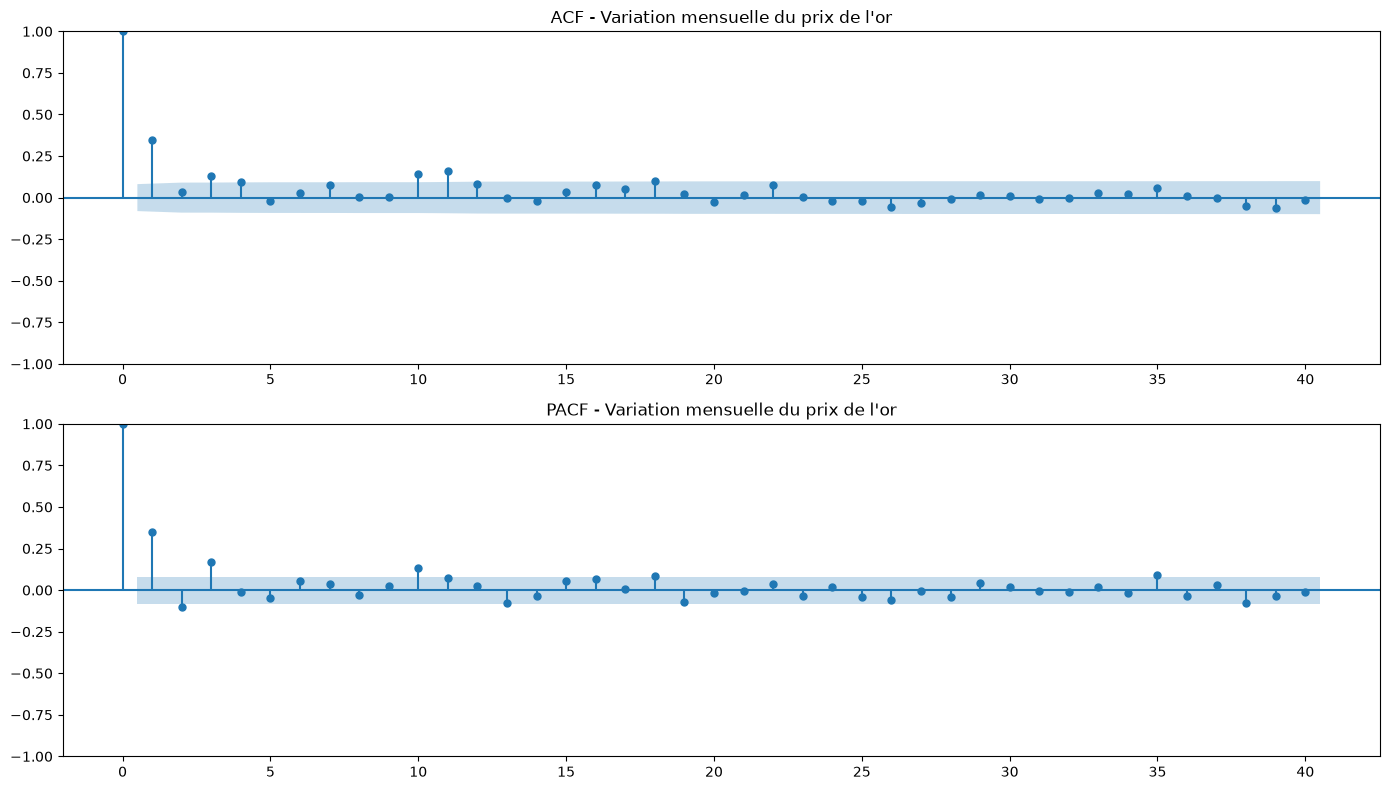

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(
    df["USD_diff"].dropna(),
    lags=40,
    ax=axes[0]
)

axes[0].set_title("ACF - Variation mensuelle du prix de l'or")

plot_pacf(
    df["USD_diff"].dropna(),
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF - Variation mensuelle du prix de l'or")

plt.tight_layout()
plt.show()

In [17]:
df["Month"] = df["Date"].dt.month

monthly_returns = df.groupby("Month")["USD_return"].mean()

print(monthly_returns)

Month
1     0.016873
2     0.021270
3    -0.003277
4    -0.004685
5     0.004433
6    -0.003176
7    -0.000360
8     0.009739
9     0.010691
10    0.017567
11    0.007588
12   -0.001491
Name: USD_return, dtype: float64


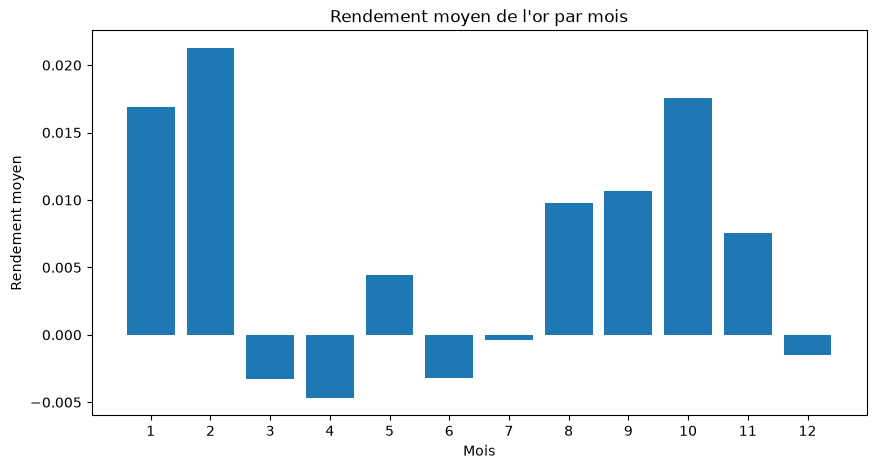

In [18]:
plt.figure(figsize=(10, 5))

plt.bar(monthly_returns.index, monthly_returns.values)

plt.title("Rendement moyen de l'or par mois")
plt.xlabel("Mois")
plt.ylabel("Rendement moyen")

plt.xticks(range(1, 13))

plt.show()

In [14]:
# Garder uniquement les variables nécessaires
gold = df[["Date", "USD"]].copy()

# S'assurer que les données sont triées
gold = gold.sort_values("Date").reset_index(drop=True)

# Nombre de mois dans le test
test_size = 12

# Séparation temporelle
train = gold.iloc[:-test_size].copy()
test = gold.iloc[-test_size:].copy()

print("Train :", train.shape)
print("Test  :", test.shape)

print("\nPériode TRAIN :")
print(train["Date"].min(), "→", train["Date"].max())

print("\nPériode TEST :")
print(test["Date"].min(), "→", test["Date"].max())

Train : (573, 2)
Test  : (12, 2)

Période TRAIN :
1978-01-31 00:00:00 → 2025-09-30 00:00:00

Période TEST :
2025-10-31 00:00:00 → 2026-09-30 00:00:00


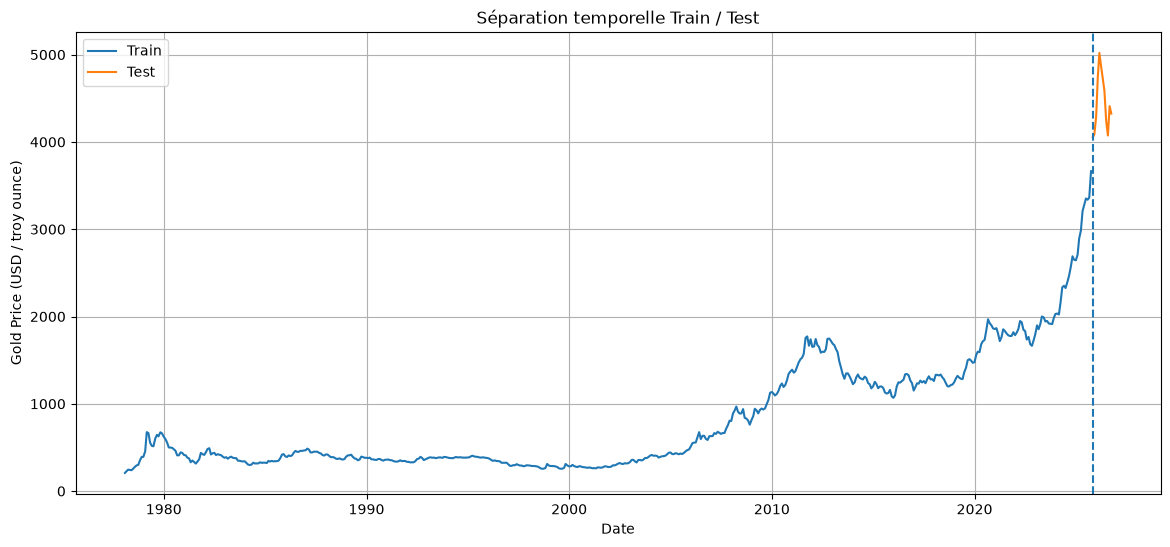

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(train["Date"], train["USD"], label="Train")
plt.plot(test["Date"], test["USD"], label="Test")

plt.axvline(
    test["Date"].iloc[0],
    linestyle="--"
)

plt.title("Séparation temporelle Train / Test")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD / troy ounce)")
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# Prévision naïve
test["Naive_Prediction"] = train["USD"].iloc[-1]

for i in range(len(test)):
    if i > 0:
        test.loc[test.index[i], "Naive_Prediction"] = test["USD"].iloc[i-1]

print(test)

          Date      USD  Naive_Prediction
573 2025-10-31  4053.28           3665.20
574 2025-11-28  4082.95           4053.28
575 2025-12-31  4289.48           4082.95
576 2026-01-30  4744.46           4289.48
577 2026-02-27  5019.53           4744.46
578 2026-03-31  4862.17           5019.53
579 2026-04-30  4723.88           4862.17
580 2026-05-29  4587.52           4723.88
581 2026-06-30  4238.32           4587.52
582 2026-07-31  4073.92           4238.32
583 2026-08-31  4409.89           4073.92
584 2026-09-30  4324.72           4409.89


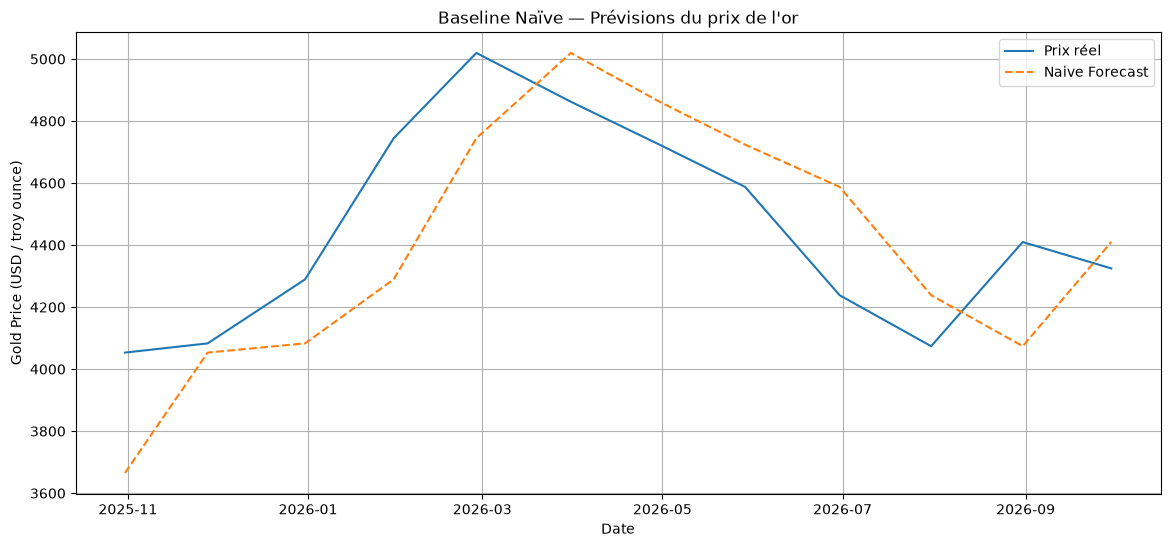

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    test["Date"],
    test["USD"],
    label="Prix réel"
)

plt.plot(
    test["Date"],
    test["Naive_Prediction"],
    label="Naive Forecast",
    linestyle="--"
)

plt.title("Baseline Naïve — Prévisions du prix de l'or")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD / troy ounce)")
plt.legend()
plt.grid(True)

plt.show()

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    test["USD"],
    test["Naive_Prediction"]
)

rmse = np.sqrt(
    mean_squared_error(
        test["USD"],
        test["Naive_Prediction"]
    )
)

mape = np.mean(
    np.abs(
        (test["USD"] - test["Naive_Prediction"])
        / test["USD"]
    )
) * 100

print(f"MAE  : {mae:.2f} USD")
print(f"RMSE : {rmse:.2f} USD")
print(f"MAPE : {mape:.2f}%")

MAE  : 226.76 USD
RMSE : 259.55 USD
MAPE : 5.10%


In [31]:
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")

In [32]:
results = []

for p in range(0, 4):
    for q in range(0, 4):

        try:
            model = ARIMA(
                train["USD"],
                order=(p, 1, q)
            )

            fitted_model = model.fit()

            results.append({
                "p": p,
                "d": 1,
                "q": q,
                "AIC": fitted_model.aic
            })

        except Exception as e:
            print(f"ARIMA({p},1,{q}) impossible : {e}")

In [33]:
arima_results = pd.DataFrame(results)

arima_results = arima_results.sort_values("AIC")

print(arima_results)

    p  d  q          AIC
11  2  1  3  5780.957552
13  3  1  1  5781.046536
10  2  1  2  5781.605835
14  3  1  2  5781.708699
15  3  1  3  5782.296156
7   1  1  3  5782.536180
6   1  1  2  5787.522576
9   2  1  1  5805.150098
1   0  1  1  5810.959971
12  3  1  0  5811.207482
5   1  1  1  5812.880271
2   0  1  2  5812.912986
4   1  1  0  5813.028036
3   0  1  3  5813.082538
8   2  1  0  5813.905096
0   0  1  0  5859.939052


In [34]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

orders = [
    (2, 1, 3),
    (3, 1, 1),
    (2, 1, 2)
]

arima_test_results = []

for order in orders:

    print(f"ARIMA{order}")

    model = ARIMA(
        train["USD"],
        order=order
    )

    fitted_model = model.fit()

    # Prévisions sur les 12 mois du test
    forecast = fitted_model.forecast(
        steps=len(test)
    )

    # Métriques
    mae = mean_absolute_error(
        test["USD"],
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            test["USD"],
            forecast
        )
    )

    mape = np.mean(
        np.abs(
            (test["USD"] - forecast)
            / test["USD"]
        )
    ) * 100

    arima_test_results.append({
        "Model": f"ARIMA{order}",
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

ARIMA(2, 1, 3)
ARIMA(3, 1, 1)
ARIMA(2, 1, 2)


In [35]:
arima_test_results = pd.DataFrame(arima_test_results)

print(
    arima_test_results.sort_values("MAE")
)


            Model         MAE        RMSE      MAPE
0  ARIMA(2, 1, 3)  406.703907  498.642707  8.826591
1  ARIMA(3, 1, 1)  412.756645  486.561249  9.001964
2  ARIMA(2, 1, 2)  414.338754  502.939486  9.006376


In [36]:
comparison = pd.concat([
    pd.DataFrame([{
        "Model": "Naive",
        "MAE": 226.76,
        "RMSE": 259.55,
        "MAPE": 5.10
    }]),
    arima_test_results
], ignore_index=True)

print(comparison.sort_values("MAE"))

            Model         MAE        RMSE      MAPE
0           Naive  226.760000  259.550000  5.100000
1  ARIMA(2, 1, 3)  406.703907  498.642707  8.826591
2  ARIMA(3, 1, 1)  412.756645  486.561249  9.001964
3  ARIMA(2, 1, 2)  414.338754  502.939486  9.006376


AIC sert à sélectionner des modèles parmi les candidats sur les données d'entraînement, mais les métriques sur des données futures servent à juger la capacité de prévision.

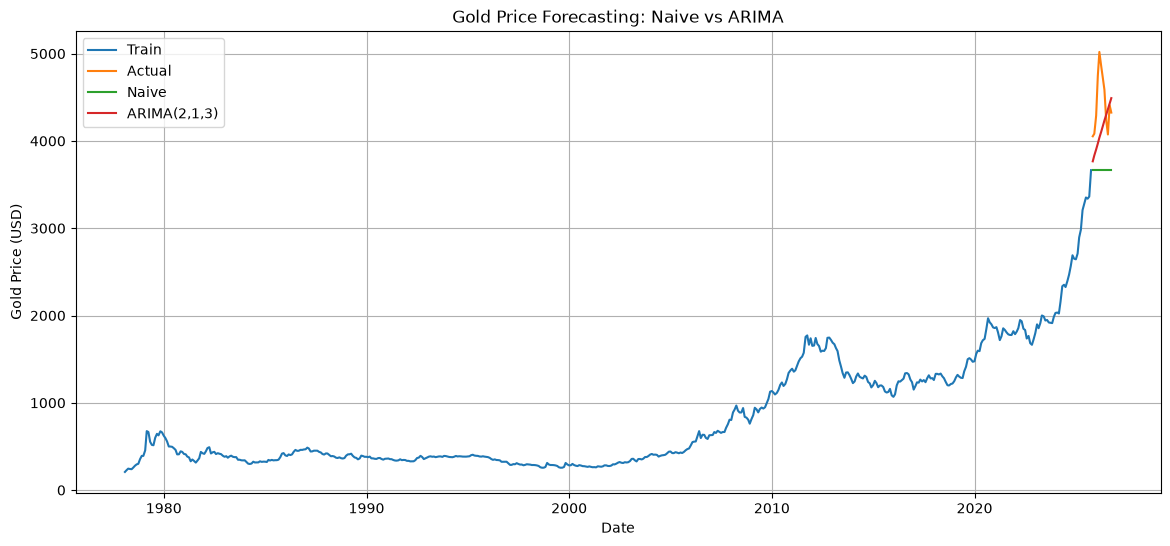

In [37]:


best_arima = ARIMA(train["USD"], order=(2, 1, 3)).fit()

arima_forecast = best_arima.forecast(steps=len(test))

naive_forecast = train["USD"].iloc[-1]

plt.figure(figsize=(14, 6))

plt.plot(train["Date"], train["USD"], label="Train")
plt.plot(test["Date"], test["USD"], label="Actual")
plt.plot(
    test["Date"],
    [naive_forecast] * len(test),
    label="Naive"
)
plt.plot(
    test["Date"],
    arima_forecast,
    label="ARIMA(2,1,3)"
)

plt.xlabel("Date")
plt.ylabel("Gold Price (USD)")
plt.title("Gold Price Forecasting: Naive vs ARIMA")
plt.legend()
plt.grid(True)
plt.show()

Wlak-forward validation

In [38]:
from sklearn.model_selection import TimeSeriesSplit

X = gold[["USD"]]
y = gold["USD"]

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

for i, (train_idx, val_idx) in enumerate(tscv.split(X), 1):
    print(f"Split {i}")
    print("Train :", gold.iloc[train_idx]["Date"].min(),
          "→", gold.iloc[train_idx]["Date"].max())
    print("Valid :", gold.iloc[val_idx]["Date"].min(),
          "→", gold.iloc[val_idx]["Date"].max())
    print()

Split 1
Train : 1978-01-31 00:00:00 → 2021-09-30 00:00:00
Valid : 2021-10-29 00:00:00 → 2022-09-30 00:00:00

Split 2
Train : 1978-01-31 00:00:00 → 2022-09-30 00:00:00
Valid : 2022-10-31 00:00:00 → 2023-09-29 00:00:00

Split 3
Train : 1978-01-31 00:00:00 → 2023-09-29 00:00:00
Valid : 2023-10-31 00:00:00 → 2024-09-30 00:00:00

Split 4
Train : 1978-01-31 00:00:00 → 2024-09-30 00:00:00
Valid : 2024-10-31 00:00:00 → 2025-09-30 00:00:00

Split 5
Train : 1978-01-31 00:00:00 → 2025-09-30 00:00:00
Valid : 2025-10-31 00:00:00 → 2026-09-30 00:00:00



NAIVE

In [39]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

naive_results = []

for i, (train_idx, val_idx) in enumerate(tscv.split(gold), 1):

    train_split = gold.iloc[train_idx]
    val_split = gold.iloc[val_idx]

    # Naive = dernier prix connu
    last_value = train_split["USD"].iloc[-1]

    forecast = np.repeat(last_value, len(val_split))

    mae = mean_absolute_error(val_split["USD"], forecast)
    rmse = np.sqrt(mean_squared_error(val_split["USD"], forecast))
    mape = np.mean(
        np.abs((val_split["USD"] - forecast) / val_split["USD"])
    ) * 100

    naive_results.append({
        "Split": i,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

naive_results = pd.DataFrame(naive_results)

print(naive_results)

print("\nMoyenne :")
print(naive_results[["MAE", "RMSE", "MAPE"]].mean())

   Split         MAE        RMSE       MAPE
0      1   64.414167   82.828711   3.478669
1      2  201.193333  221.414747  10.455575
2      3  299.297500  363.739774  12.750207
3      4  497.585833  598.205503  15.246148
4      5  785.643333  846.715304  17.242899

Moyenne :
MAE     369.626833
RMSE    422.580808
MAPE     11.834700
dtype: float64


ARIMA

In [40]:


tscv = TimeSeriesSplit(n_splits=5, test_size=12)

arima_results = []

for i, (train_idx, val_idx) in enumerate(tscv.split(gold), 1):

    train_split = gold.iloc[train_idx]
    val_split = gold.iloc[val_idx]

    # Entraînement
    model = ARIMA(
        train_split["USD"],
        order=(2, 1, 3)
    )

    fitted_model = model.fit()

    # Prévision des 12 prochains mois
    forecast = fitted_model.forecast(
        steps=len(val_split)
    )

    # Métriques
    mae = mean_absolute_error(
        val_split["USD"],
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_split["USD"],
            forecast
        )
    )

    mape = np.mean(
        np.abs(
            (val_split["USD"] - forecast)
            / val_split["USD"]
        )
    ) * 100

    arima_results.append({
        "Split": i,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

arima_results = pd.DataFrame(arima_results)

print(arima_results)

print("\nMoyenne :")
print(
    arima_results[
        ["MAE", "RMSE", "MAPE"]
    ].mean()
)

   Split         MAE        RMSE       MAPE
0      1   63.044759   80.316973   3.417284
1      2  241.818198  265.495825  12.570157
2      3  287.434082  350.653151  12.236042
3      4  473.691965  577.079706  14.467153
4      5  406.703907  498.642707   8.826591

Moyenne :
MAE     294.538582
RMSE    354.437672
MAPE     10.303446
dtype: float64


SEASONAL NAIVE

In [41]:
seasonal_naive_results = []

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

for i, (train_idx, val_idx) in enumerate(tscv.split(gold), 1):

    train_split = gold.iloc[train_idx]
    val_split = gold.iloc[val_idx]

    # Les 12 derniers mois du train
    last_12_months = train_split["USD"].iloc[-12:].values

    # Répéter ces 12 valeurs comme prévision
    forecast = last_12_months

    mae = mean_absolute_error(
        val_split["USD"],
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_split["USD"],
            forecast
        )
    )

    mape = np.mean(
        np.abs(
            (val_split["USD"] - forecast)
            / val_split["USD"]
        )
    ) * 100

    seasonal_naive_results.append({
        "Split": i,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

seasonal_naive_results = pd.DataFrame(
    seasonal_naive_results
)

print(seasonal_naive_results)

print("\nMoyenne :")
print(
    seasonal_naive_results[
        ["MAE", "RMSE", "MAPE"]
    ].mean()
)

   Split          MAE         RMSE       MAPE
0      1    77.095000   101.396151   4.189233
1      2   104.445833   125.718316   5.517300
2      3   334.527500   365.418878  14.686320
3      4   849.101667   860.580623  27.566146
4      5  1386.137500  1462.716629  30.794731

Moyenne :
MAE     550.261500
RMSE    583.166119
MAPE     16.550746
dtype: float64


In [42]:
comparison_cv = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,1,3)"
    ],
    "MAE": [
        369.626833,
        550.261500,
        294.538582
    ],
    "RMSE": [
        422.580808,
        583.166119,
        354.437672
    ],
    "MAPE": [
        11.834700,
        16.550746,
        10.303446
    ]
})

comparison_cv = comparison_cv.sort_values("MAE")

print(comparison_cv)

            Model         MAE        RMSE       MAPE
2    ARIMA(2,1,3)  294.538582  354.437672  10.303446
0           Naive  369.626833  422.580808  11.834700
1  Seasonal Naive  550.261500  583.166119  16.550746


In [43]:
gold_ml = gold.copy()

# Lags
gold_ml["lag_1"] = gold_ml["USD"].shift(1)
gold_ml["lag_2"] = gold_ml["USD"].shift(2)
gold_ml["lag_3"] = gold_ml["USD"].shift(3)
gold_ml["lag_6"] = gold_ml["USD"].shift(6)
gold_ml["lag_12"] = gold_ml["USD"].shift(12)

# Rolling means
gold_ml["rolling_mean_3"] = (
    gold_ml["USD"].shift(1).rolling(3).mean()
)

gold_ml["rolling_mean_6"] = (
    gold_ml["USD"].shift(1).rolling(6).mean()
)

gold_ml["rolling_mean_12"] = (
    gold_ml["USD"].shift(1).rolling(12).mean()
)

# Rolling standard deviation
gold_ml["rolling_std_3"] = (
    gold_ml["USD"].shift(1).rolling(3).std()
)

gold_ml["rolling_std_6"] = (
    gold_ml["USD"].shift(1).rolling(6).std()
)

gold_ml["rolling_std_12"] = (
    gold_ml["USD"].shift(1).rolling(12).std()
)

# Mois
gold_ml["month"] = gold_ml["Date"].dt.month

In [44]:
gold_ml = gold_ml.dropna().reset_index(drop=True)

In [45]:
print(gold_ml.shape)
print(gold_ml.isna().sum())
print(gold_ml.head())

(573, 14)
Date               0
USD                0
lag_1              0
lag_2              0
lag_3              0
lag_6              0
lag_12             0
rolling_mean_3     0
rolling_mean_6     0
rolling_mean_12    0
rolling_std_3      0
rolling_std_6      0
rolling_std_12     0
month              0
dtype: int64
        Date     USD   lag_1   lag_2   lag_3   lag_6  lag_12  rolling_mean_3  \
0 1979-01-31  455.08  391.99  391.66  355.11  279.07  207.83      379.586667   
1 1979-02-28  675.31  455.08  391.99  391.66  294.74  227.27      412.910000   
2 1979-03-30  665.32  675.31  455.08  391.99  300.82  245.67      507.460000   
3 1979-04-30  553.58  665.32  675.31  455.08  355.11  242.05      598.570000   
4 1979-05-31  517.41  553.58  665.32  675.31  391.66  239.16      631.403333   

   rolling_mean_6  rolling_mean_12  rolling_std_3  rolling_std_6  \
0      335.565000       286.082500      21.198057      50.552977   
1      364.900000       306.686667      36.520664      61.166844  

In [46]:
features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_6",
    "lag_12",
    "rolling_mean_3",
    "rolling_mean_6",
    "rolling_mean_12",
    "rolling_std_3",
    "rolling_std_6",
    "rolling_std_12",
    "month"
]

X = gold_ml[features]
y = gold_ml["USD"]

print("X shape :", X.shape)
print("y shape :", y.shape)
print("\nFeatures :")
print(X.columns.tolist())

X shape : (573, 12)
y shape : (573,)

Features :
['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3', 'rolling_std_6', 'rolling_std_12', 'month']


In [47]:
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

xgb_results = []

for i, (train_idx, val_idx) in enumerate(tscv.split(X), 1):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    # Modèle XGBoost
    model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    # Entraînement
    model.fit(X_train, y_train)

    # Prévision
    forecast = model.predict(X_val)

    # Métriques
    mae = mean_absolute_error(y_val, forecast)

    rmse = np.sqrt(
        mean_squared_error(y_val, forecast)
    )

    mape = np.mean(
        np.abs((y_val - forecast) / y_val)
    ) * 100

    xgb_results.append({
        "Split": i,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

xgb_results = pd.DataFrame(xgb_results)

print(xgb_results)

print("\nMoyenne :")
print(
    xgb_results[
        ["MAE", "RMSE", "MAPE"]
    ].mean()
)

   Split          MAE         RMSE       MAPE
0      1    65.749376    81.173197   3.579509
1      2    77.727361    86.076658   4.080560
2      3   346.831492   400.954948  14.937135
3      4   589.781863   679.401856  18.274082
4      5  1107.178498  1155.627316  24.479102

Moyenne :
MAE     437.453718
RMSE    480.646795
MAPE     13.070078
dtype: float64


In [48]:
# Split 5
train_idx, val_idx = list(
    TimeSeriesSplit(n_splits=5, test_size=12).split(X)
)[4]

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

xgb_forecast = model.predict(X_val)

comparison_split5 = pd.DataFrame({
    "Date": gold_ml.iloc[val_idx]["Date"].values,
    "Actual": y_val.values,
    "XGBoost": xgb_forecast
})

print(comparison_split5)

         Date   Actual      XGBoost
0  2025-10-31  4053.28  3375.535645
1  2025-11-28  4082.95  3350.415039
2  2025-12-31  4289.48  3349.272217
3  2026-01-30  4744.46  3314.892578
4  2026-02-27  5019.53  3325.430176
5  2026-03-31  4862.17  3325.026367
6  2026-04-30  4723.88  3322.388428
7  2026-05-29  4587.52  3334.781250
8  2026-06-30  4238.32  3342.697266
9  2026-07-31  4073.92  3351.939941
10 2026-08-31  4409.89  3352.010742
11 2026-09-30  4324.72  3379.588379


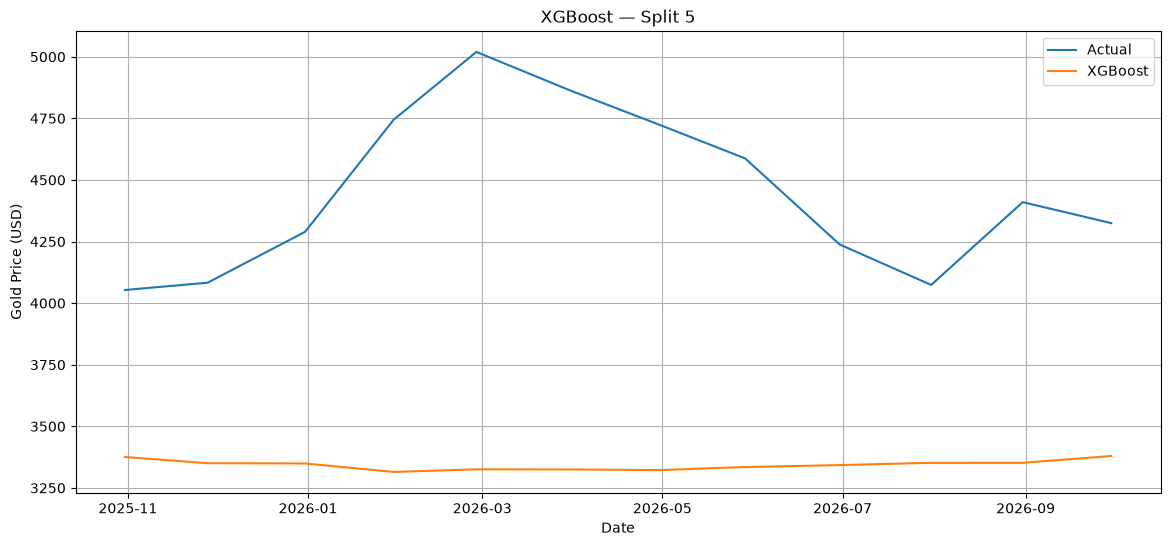

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    comparison_split5["Date"],
    comparison_split5["Actual"],
    label="Actual"
)

plt.plot(
    comparison_split5["Date"],
    comparison_split5["XGBoost"],
    label="XGBoost"
)

plt.xlabel("Date")
plt.ylabel("Gold Price (USD)")
plt.title("XGBoost — Split 5")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

gold_return = gold[["Date", "USD"]].copy()

# Rendement mensuel
gold_return["return"] = gold_return["USD"].pct_change()

# Lags des rendements
gold_return["return_lag_1"] = gold_return["return"].shift(1)
gold_return["return_lag_2"] = gold_return["return"].shift(2)
gold_return["return_lag_3"] = gold_return["return"].shift(3)
gold_return["return_lag_6"] = gold_return["return"].shift(6)
gold_return["return_lag_12"] = gold_return["return"].shift(12)

# Moyennes mobiles des rendements
gold_return["return_mean_3"] = (
    gold_return["return"].shift(1).rolling(3).mean()
)

gold_return["return_mean_6"] = (
    gold_return["return"].shift(1).rolling(6).mean()
)

gold_return["return_mean_12"] = (
    gold_return["return"].shift(1).rolling(12).mean()
)

# Volatilité
gold_return["return_std_3"] = (
    gold_return["return"].shift(1).rolling(3).std()
)

gold_return["return_std_6"] = (
    gold_return["return"].shift(1).rolling(6).std()
)

gold_return["return_std_12"] = (
    gold_return["return"].shift(1).rolling(12).std()
)

# Mois
gold_return["month"] = gold_return["Date"].dt.month

# Supprimer les valeurs manquantes
gold_return = gold_return.dropna().reset_index(drop=True)

gold_return.head()

,Date,USD,return,return_lag_1,return_lag_2,return_lag_3,return_lag_6,return_lag_12,return_mean_3,return_mean_6,return_mean_12,return_std_3,return_std_6,return_std_12,month
0,1979-02-28,675.31,0.483937,0.160948,0.000843,0.102926,0.056151,0.093538,0.088239,0.086995,0.069187,0.081057,0.073809,0.063073,2
1,1979-03-30,665.32,-0.014793,0.483937,0.160948,0.000843,0.020628,0.080961,0.215242,0.158293,0.101720,0.246081,0.175129,0.135675,3
2,1979-04-30,553.58,-0.167949,-0.014793,0.483937,0.160948,0.180473,-0.014735,0.210031,0.152389,0.093741,0.252962,0.181190,0.139761,4
3,1979-05-31,517.41,-0.065338,-0.167949,-0.014793,0.483937,0.102926,-0.011940,0.100398,0.094318,0.080973,0.340868,0.221695,0.156560,5
4,1979-06-29,513.82,-0.006938,-0.065338,-0.167949,-0.014793,0.000843,0.077187,-0.082694,0.066274,0.076523,0.078039,0.230842,0.160159,6


In [16]:
features_return = [
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_6",
    "return_lag_12",
    "return_mean_3",
    "return_mean_6",
    "return_mean_12",
    "return_std_3",
    "return_std_6",
    "return_std_12",
    "month"
]

X_return = gold_return[features_return]
y_return = gold_return["return"]

print("X shape:", X_return.shape)
print("y shape:", y_return.shape)
print("Missing:", X_return.isna().sum().sum())

X shape: (572, 12)
y shape: (572,)
Missing: 0


In [45]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

results_xgb_return = []
predictions_xgb_return = []

for split, (train_idx, val_idx) in enumerate(tscv.split(gold_return), start=1):

    train_data = gold_return.iloc[train_idx].copy()
    val_data = gold_return.iloc[val_idx].copy()

    # Historique disponible au moment du forecast
    history = train_data[["Date", "USD", "return"]].copy()

    X_train = train_data[features_return]
    y_train = train_data["return"]

    # Modèle
    model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    model.fit(X_train, y_train)

    predicted_prices = []

    # Prévision récursive sur les 12 mois
    for i in range(len(val_data)):

        # Rendements disponibles dans l'historique
        returns = history["return"]

        # Construire les features uniquement avec le passé
        X_future = pd.DataFrame([{
            "return_lag_1": returns.iloc[-1],
            "return_lag_2": returns.iloc[-2],
            "return_lag_3": returns.iloc[-3],
            "return_lag_6": returns.iloc[-6],
            "return_lag_12": returns.iloc[-12],

            "return_mean_3": returns.iloc[-3:].mean(),
            "return_mean_6": returns.iloc[-6:].mean(),
            "return_mean_12": returns.iloc[-12:].mean(),

            "return_std_3": returns.iloc[-3:].std(),
            "return_std_6": returns.iloc[-6:].std(),
            "return_std_12": returns.iloc[-12:].std(),

            "month": val_data.iloc[i]["Date"].month
        }])

        # Prédire le rendement
        predicted_return = model.predict(X_future)[0]

        # Dernier prix connu/prédit
        previous_price = history["USD"].iloc[-1]

        # Reconstruire le prix
        predicted_price = previous_price * (1 + predicted_return)

        predicted_prices.append(predicted_price)

        # Ajouter la prédiction à l'historique
        new_row = pd.DataFrame({
            "Date": [val_data.iloc[i]["Date"]],
            "USD": [predicted_price],
            "return": [predicted_return]
        })

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    # Vraies valeurs
    actual = val_data["USD"].values
    predicted = np.array(predicted_prices)

    # Métriques
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100

    results_xgb_return.append({
        "Split": split,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

    predictions_xgb_return.append({
        "Split": split,
        "Date": val_data["Date"].values,
        "Actual": actual,
        "Predicted": predicted
    })

results_xgb_return_df = pd.DataFrame(results_xgb_return)

print(results_xgb_return_df)

   Split         MAE        RMSE       MAPE
0      1  104.419352  157.509625   5.931358
1      2  155.484550  175.876635   8.062169
2      3   89.588348  112.300090   3.818240
3      4  140.202788  178.913403   4.354599
4      5  490.649157  621.563074  10.559519


In [20]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [46]:
print("Moyenne des 5 splits :")

print(
    results_xgb_return_df[
        ["MAE", "RMSE", "MAPE"]
    ].mean()
)

Moyenne des 5 splits :
MAE     196.068839
RMSE    249.232565
MAPE      6.545177
dtype: float64


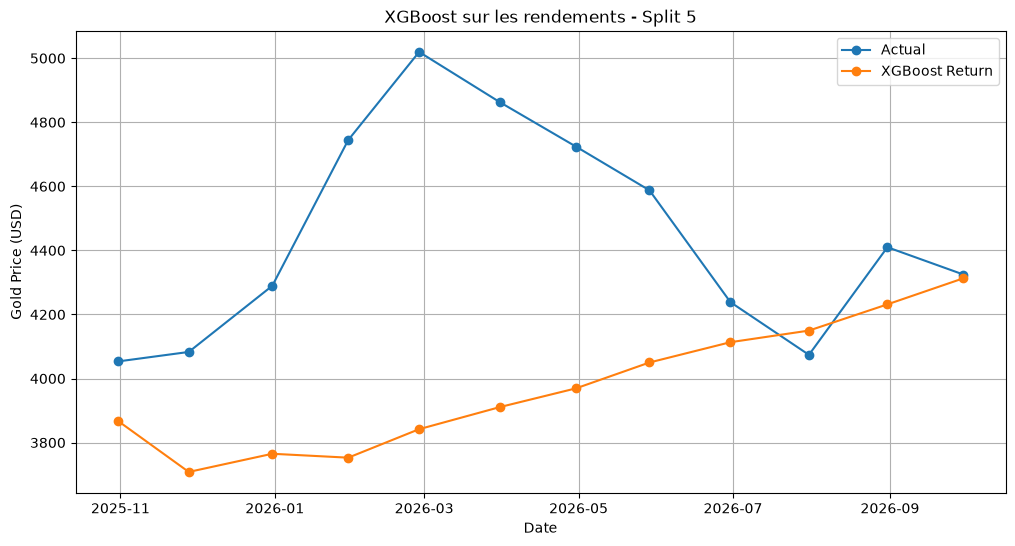

In [47]:
import matplotlib.pyplot as plt

last_result = predictions_xgb_return[-1]

dates = pd.to_datetime(last_result["Date"])
actual = last_result["Actual"]
predicted = last_result["Predicted"]

plt.figure(figsize=(12, 6))

plt.plot(
    dates,
    actual,
    marker="o",
    label="Actual"
)

plt.plot(
    dates,
    predicted,
    marker="o",
    label="XGBoost Return"
)

plt.title("XGBoost sur les rendements - Split 5")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD)")
plt.legend()
plt.grid(True)

plt.show()

In [48]:
comparison_xgb_return = pd.DataFrame({
    "Date": dates,
    "Actual": actual,
    "XGBoost_Return": predicted
})

print(comparison_xgb_return)

         Date   Actual  XGBoost_Return
0  2025-10-31  4053.28     3867.850159
1  2025-11-28  4082.95     3708.328581
2  2025-12-31  4289.48     3765.077634
3  2026-01-30  4744.46     3752.893409
4  2026-02-27  5019.53     3841.822663
5  2026-03-31  4862.17     3911.040988
6  2026-04-30  4723.88     3969.350811
7  2026-05-29  4587.52     4050.018186
8  2026-06-30  4238.32     4113.405936
9  2026-07-31  4073.92     4149.636394
10 2026-08-31  4409.89     4231.511572
11 2026-09-30  4324.72     4312.826573


In [58]:
gold_v2 = gold[["Date", "USD"]].copy()

# Rendement
gold_v2["return"] = gold_v2["USD"].pct_change()

# -----------------------------
# Lags des rendements
# -----------------------------
gold_v2["return_lag_1"] = gold_v2["return"].shift(1)
gold_v2["return_lag_2"] = gold_v2["return"].shift(2)
gold_v2["return_lag_3"] = gold_v2["return"].shift(3)
gold_v2["return_lag_6"] = gold_v2["return"].shift(6)
gold_v2["return_lag_12"] = gold_v2["return"].shift(12)

# -----------------------------
# Moyennes des rendements
# -----------------------------
gold_v2["return_mean_3"] = (
    gold_v2["return"].shift(1).rolling(3).mean()
)

gold_v2["return_mean_6"] = (
    gold_v2["return"].shift(1).rolling(6).mean()
)

gold_v2["return_mean_12"] = (
    gold_v2["return"].shift(1).rolling(12).mean()
)

# -----------------------------
# Volatilité
# -----------------------------
gold_v2["return_std_3"] = (
    gold_v2["return"].shift(1).rolling(3).std()
)

gold_v2["return_std_6"] = (
    gold_v2["return"].shift(1).rolling(6).std()
)

gold_v2["return_std_12"] = (
    gold_v2["return"].shift(1).rolling(12).std()
)

# -----------------------------
# Niveau du prix
# -----------------------------
gold_v2["price_lag_1"] = gold_v2["USD"].shift(1)
gold_v2["price_lag_3"] = gold_v2["USD"].shift(3)
gold_v2["price_lag_6"] = gold_v2["USD"].shift(6)
gold_v2["price_lag_12"] = gold_v2["USD"].shift(12)

# -----------------------------
# Moyennes mobiles du prix
# -----------------------------
gold_v2["price_mean_3"] = (
    gold_v2["USD"].shift(1).rolling(3).mean()
)

gold_v2["price_mean_6"] = (
    gold_v2["USD"].shift(1).rolling(6).mean()
)

gold_v2["price_mean_12"] = (
    gold_v2["USD"].shift(1).rolling(12).mean()
)

# -----------------------------
# Tendances du prix
# -----------------------------
gold_v2["price_change_3"] = (
    gold_v2["USD"].shift(1) /
    gold_v2["USD"].shift(4) - 1
)

gold_v2["price_change_6"] = (
    gold_v2["USD"].shift(1) /
    gold_v2["USD"].shift(7) - 1
)

gold_v2["price_change_12"] = (
    gold_v2["USD"].shift(1) /
    gold_v2["USD"].shift(13) - 1
)

# Mois
gold_v2["month"] = gold_v2["Date"].dt.month

# Supprimer les lignes incomplètes
gold_v2 = gold_v2.dropna().reset_index(drop=True)

print("Shape:", gold_v2.shape)
print("Missing:", gold_v2.isna().sum().sum())

Shape: (572, 25)
Missing: 0


In [59]:
features_v2 = [
    # Rendements
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_6",
    "return_lag_12",

    "return_mean_3",
    "return_mean_6",
    "return_mean_12",

    "return_std_3",
    "return_std_6",
    "return_std_12",

    # Prix
    "price_lag_1",
    "price_lag_3",
    "price_lag_6",
    "price_lag_12",

    "price_mean_3",
    "price_mean_6",
    "price_mean_12",

    # Tendances
    "price_change_3",
    "price_change_6",
    "price_change_12",

    # Saison
    "month"
]

X_v2 = gold_v2[features_v2]
y_v2 = gold_v2["return"]

print("X shape:", X_v2.shape)
print("y shape:", y_v2.shape)
print("Missing:", X_v2.isna().sum().sum())

X shape: (572, 22)
y shape: (572,)
Missing: 0


In [61]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=5, test_size=12)

results_xgb_v2 = []
predictions_xgb_v2 = []

for split, (train_idx, val_idx) in enumerate(tscv.split(gold_v2), start=1):

    train_data = gold_v2.iloc[train_idx].copy()
    val_data = gold_v2.iloc[val_idx].copy()

    # Historique disponible
    history = train_data[["Date", "USD", "return"]].copy()

    X_train = train_data[features_v2]
    y_train = train_data["return"]

    # Modèle
    model = XGBRegressor(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    )

    model.fit(X_train, y_train)

    predicted_prices = []

    # Forecast récursif 12 mois
    for i in range(len(val_data)):

        returns = history["return"]
        prices = history["USD"]

        # Features construites uniquement avec l'historique
        X_future = pd.DataFrame([{

            # Rendements
            "return_lag_1": returns.iloc[-1],
            "return_lag_2": returns.iloc[-2],
            "return_lag_3": returns.iloc[-3],
            "return_lag_6": returns.iloc[-6],
            "return_lag_12": returns.iloc[-12],

            "return_mean_3": returns.iloc[-3:].mean(),
            "return_mean_6": returns.iloc[-6:].mean(),
            "return_mean_12": returns.iloc[-12:].mean(),

            "return_std_3": returns.iloc[-3:].std(),
            "return_std_6": returns.iloc[-6:].std(),
            "return_std_12": returns.iloc[-12:].std(),

            # Prix
            "price_lag_1": prices.iloc[-1],
            "price_lag_3": prices.iloc[-3],
            "price_lag_6": prices.iloc[-6],
            "price_lag_12": prices.iloc[-12],

            "price_mean_3": prices.iloc[-3:].mean(),
            "price_mean_6": prices.iloc[-6:].mean(),
            "price_mean_12": prices.iloc[-12:].mean(),

            # Tendances
            "price_change_3": prices.iloc[-1] / prices.iloc[-4] - 1,
            "price_change_6": prices.iloc[-1] / prices.iloc[-7] - 1,
            "price_change_12": prices.iloc[-1] / prices.iloc[-13] - 1,

            # Mois
            "month": val_data.iloc[i]["Date"].month
        }])

        # Prédiction du rendement
        predicted_return = model.predict(X_future)[0]

        # Reconstruction du prix
        previous_price = prices.iloc[-1]

        predicted_price = previous_price * (1 + predicted_return)

        predicted_prices.append(predicted_price)

        # Ajouter la prédiction à l'historique
        new_row = pd.DataFrame({
            "Date": [val_data.iloc[i]["Date"]],
            "USD": [predicted_price],
            "return": [predicted_return]
        })

        history = pd.concat(
            [history, new_row],
            ignore_index=True
        )

    # Valeurs réelles
    actual = val_data["USD"].values
    predicted = np.array(predicted_prices)

    # Métriques
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    results_xgb_v2.append({
        "Split": split,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })

    predictions_xgb_v2.append({
        "Split": split,
        "Date": val_data["Date"].values,
        "Actual": actual,
        "Predicted": predicted
    })


results_xgb_v2_df = pd.DataFrame(results_xgb_v2)

print(results_xgb_v2_df)


   Split         MAE        RMSE       MAPE
0      1   81.107361  111.534962   4.516425
1      2  222.638017  247.715249  11.559636
2      3  413.569882  465.996259  17.931927
3      4   89.472146  103.485091   2.956992
4      5  539.714440  633.813077  11.766470


In [62]:
print("Moyenne des 5 splits :")

print(
    results_xgb_v2_df[
        ["MAE", "RMSE", "MAPE"]
    ].mean()
)

Moyenne des 5 splits :
MAE     269.300369
RMSE    312.508928
MAPE      9.746290
dtype: float64


In [63]:
param_configs = [
    {
        "name": "Baseline",
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 1,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Shallow",
        "n_estimators": 500,
        "max_depth": 2,
        "learning_rate": 0.03,
        "min_child_weight": 1,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Deeper",
        "n_estimators": 300,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 1,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "Regularized",
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.03,
        "min_child_weight": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8
    },
    {
        "name": "MoreSamples",
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.03,
        "min_child_weight": 1,
        "subsample": 1.0,
        "colsample_bytree": 1.0
    }
]

In [64]:
def evaluate_xgb_return(params):

    tscv = TimeSeriesSplit(n_splits=5, test_size=12)

    split_results = []

    for split, (train_idx, val_idx) in enumerate(
        tscv.split(gold_return), start=1
    ):

        train_data = gold_return.iloc[train_idx].copy()
        val_data = gold_return.iloc[val_idx].copy()

        history = train_data[
            ["Date", "USD", "return"]
        ].copy()

        X_train = train_data[features_return]
        y_train = train_data["return"]

        model = XGBRegressor(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            learning_rate=params["learning_rate"],
            min_child_weight=params["min_child_weight"],
            subsample=params["subsample"],
            colsample_bytree=params["colsample_bytree"],
            objective="reg:squarederror",
            random_state=42
        )

        model.fit(X_train, y_train)

        predicted_prices = []

        for i in range(len(val_data)):

            returns = history["return"]

            X_future = pd.DataFrame([{

                "return_lag_1": returns.iloc[-1],
                "return_lag_2": returns.iloc[-2],
                "return_lag_3": returns.iloc[-3],
                "return_lag_6": returns.iloc[-6],
                "return_lag_12": returns.iloc[-12],

                "return_mean_3": returns.iloc[-3:].mean(),
                "return_mean_6": returns.iloc[-6:].mean(),
                "return_mean_12": returns.iloc[-12:].mean(),

                "return_std_3": returns.iloc[-3:].std(),
                "return_std_6": returns.iloc[-6:].std(),
                "return_std_12": returns.iloc[-12:].std(),

                "month": val_data.iloc[i]["Date"].month
            }])

            predicted_return = model.predict(X_future)[0]

            previous_price = history["USD"].iloc[-1]

            predicted_price = (
                previous_price * (1 + predicted_return)
            )

            predicted_prices.append(predicted_price)

            new_row = pd.DataFrame({
                "Date": [val_data.iloc[i]["Date"]],
                "USD": [predicted_price],
                "return": [predicted_return]
            })

            history = pd.concat(
                [history, new_row],
                ignore_index=True
            )

        actual = val_data["USD"].values
        predicted = np.array(predicted_prices)

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )
        mape = np.mean(
            np.abs((actual - predicted) / actual)
        ) * 100

        split_results.append({
            "MAE": mae,
            "RMSE": rmse,
            "MAPE": mape
        })

    split_df = pd.DataFrame(split_results)

    return {
        "MAE": split_df["MAE"].mean(),
        "RMSE": split_df["RMSE"].mean(),
        "MAPE": split_df["MAPE"].mean()
    }

In [65]:
tuning_results = []

for params in param_configs:

    print(f"Testing: {params['name']}")

    metrics = evaluate_xgb_return(params)

    tuning_results.append({
        "Model": params["name"],
        **metrics
    })

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df.sort_values(
    by="MAE"
)

Testing: Baseline
Testing: Shallow
Testing: Deeper
Testing: Regularized
Testing: MoreSamples


,Model,MAE,RMSE,MAPE
0,Baseline,196.068839,249.232565,6.545177
1,Shallow,231.173019,290.166448,7.452944
3,Regularized,236.112493,285.120091,7.338389
4,MoreSamples,243.327123,301.349092,8.192607
2,Deeper,253.437438,297.813574,8.178027


In [67]:
print(tuning_results_df.sort_values(
    by="MAPE"
))

         Model         MAE        RMSE      MAPE
0     Baseline  196.068839  249.232565  6.545177
3  Regularized  236.112493  285.120091  7.338389
1      Shallow  231.173019  290.166448  7.452944
2       Deeper  253.437438  297.813574  8.178027
4  MoreSamples  243.327123  301.349092  8.192607


In [69]:
# Features et target
X_final = gold_return[features_return]
y_final = gold_return["return"]

# Modèle final retenu après validation + tuning
final_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

final_model.fit(X_final, y_final)

print("Modèle final entraîné.")
print("Dernière date disponible :", gold_return["Date"].iloc[-1])
print("Dernier prix connu :", gold_return["USD"].iloc[-1])

Modèle final entraîné.
Dernière date disponible : 2026-09-30 00:00:00
Dernier prix connu : 4324.72


In [70]:
future_dates = pd.date_range(
    start="2026-10-31",
    periods=12,
    freq="ME"
)

future_dates

DatetimeIndex(['2026-10-31', '2026-11-30', '2026-12-31', '2027-01-31',
               '2027-02-28', '2027-03-31', '2027-04-30', '2027-05-31',
               '2027-06-30', '2027-07-31', '2027-08-31', '2027-09-30'],
              dtype='datetime64[ns]', freq='ME')

In [72]:
# Copie de l'historique
history = gold_return[["Date", "USD", "return"]].copy()

final_predictions = []
final_returns = []

for date in future_dates:

    returns = history["return"]

    # Construction des features du mois futur
    X_future = pd.DataFrame([{
        "return_lag_1": returns.iloc[-1],
        "return_lag_2": returns.iloc[-2],
        "return_lag_3": returns.iloc[-3],
        "return_lag_6": returns.iloc[-6],
        "return_lag_12": returns.iloc[-12],

        "return_mean_3": returns.iloc[-3:].mean(),
        "return_mean_6": returns.iloc[-6:].mean(),
        "return_mean_12": returns.iloc[-12:].mean(),

        "return_std_3": returns.iloc[-3:].std(),
        "return_std_6": returns.iloc[-6:].std(),
        "return_std_12": returns.iloc[-12:].std(),

        "month": date.month
    }])

    # Prévision du rendement
    predicted_return = final_model.predict(X_future)[0]

    # Prix précédent
    previous_price = history["USD"].iloc[-1]

    # Reconstruction du prix
    predicted_price = previous_price * (1 + predicted_return)

    # Sauvegarde
    final_returns.append(predicted_return)
    final_predictions.append(predicted_price)

    # Ajouter la nouvelle observation à l'historique
    new_row = pd.DataFrame({
        "Date": [date],
        "USD": [predicted_price],
        "return": [predicted_return]
    })

    history = pd.concat([history, new_row], ignore_index=True)


# Tableau final
forecast_2026_2027 = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Return": final_returns,
    "Predicted_USD": final_predictions
})

print(forecast_2026_2027)

         Date  Predicted_Return  Predicted_USD
0  2026-10-31         -0.012619    4270.146794
1  2026-11-30          0.002176    4279.437304
2  2026-12-31         -0.011317    4231.008890
3  2027-01-31         -0.017157    4158.415628
4  2027-02-28         -0.022339    4065.522077
5  2027-03-31         -0.023242    3971.032922
6  2027-04-30         -0.010108    3930.894218
7  2027-05-31         -0.011059    3887.422514
8  2027-06-30         -0.001309    3882.335587
9  2027-07-31         -0.004299    3865.645716
10 2027-08-31          0.003838    3880.483226
11 2027-09-30         -0.002204    3871.931794


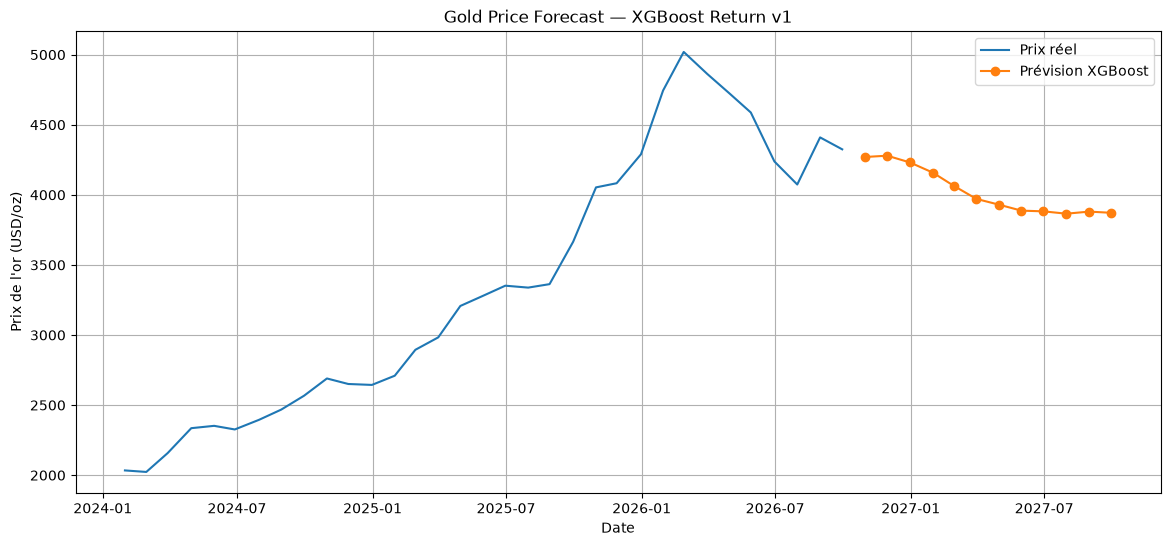

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Historique récent
recent_history = gold[gold["Date"] >= "2024-01-01"]

plt.plot(
    recent_history["Date"],
    recent_history["USD"],
    label="Prix réel"
)

# Prévision
plt.plot(
    forecast_2026_2027["Date"],
    forecast_2026_2027["Predicted_USD"],
    marker="o",
    label="Prévision XGBoost"
)

plt.title("Gold Price Forecast — XGBoost Return v1")
plt.xlabel("Date")
plt.ylabel("Prix de l'or (USD/oz)")
plt.legend()
plt.grid(True)
plt.show()

In [74]:
# Charger le taux USD/TND
fx = pd.read_csv("C://Users//MSI//Desktop//AI ENGINEER//ML ENGINEER//GOLD-PRICE-FORECASTING//usd-tnd-daily.csv")

# Conversion de la date
fx["date"] = pd.to_datetime(fx["date"])

# Moyenne mensuelle
fx_monthly = (
    fx.set_index("date")["usd_tnd"]
    .resample("ME")
    .mean()
    .reset_index()
)

fx_monthly.columns = ["Date", "USD_TND"]

print(fx_monthly)
print("//nShape :", fx_monthly.shape)
print("//nPériode :", fx_monthly["Date"].min(), "→", fx_monthly["Date"].max())

         Date   USD_TND
0  2025-09-30  2.912200
1  2025-10-31  2.929619
2  2025-11-30  2.951092
3  2025-12-31  2.917774
4  2026-01-31  2.884868
5  2026-02-28  2.863683
6  2026-03-31  2.924727
7  2026-04-30  2.902596
8  2026-05-31  2.896862
9  2026-06-30  2.933662
10 2026-07-31  2.951852
11 2026-08-31  2.918938
12 2026-09-30  2.930211
13 2026-10-31  2.993300
//nShape : (14, 2)
//nPériode : 2025-09-30 00:00:00 → 2026-10-31 00:00:00


In [75]:
results_final = pd.DataFrame({
    "Model": [
        "XGBoost Return v1",
        "ARIMA(2,1,3)",
        "Naive",
        "XGBoost Direct Price",
        "Seasonal Naive"
    ],
    "MAE": [
        196.068839,
        294.538582,
        369.626833,
        437.453718,
        550.261500
    ],
    "RMSE": [
        249.232565,
        354.437672,
        422.580808,
        480.646795,
        583.166119
    ],
    "MAPE": [
        6.545177,
        10.303446,
        11.834700,
        13.070078,
        16.550746
    ]
})

results_final = results_final.sort_values("MAE").reset_index(drop=True)

results_final.round(2)

,Model,MAE,RMSE,MAPE
0,XGBoost Return v1,196.07,249.23,6.55
1,"ARIMA(2,1,3)",294.54,354.44,10.30
2,Naive,369.63,422.58,11.83
3,XGBoost Direct Price,437.45,480.65,13.07
4,Seasonal Naive,550.26,583.17,16.55


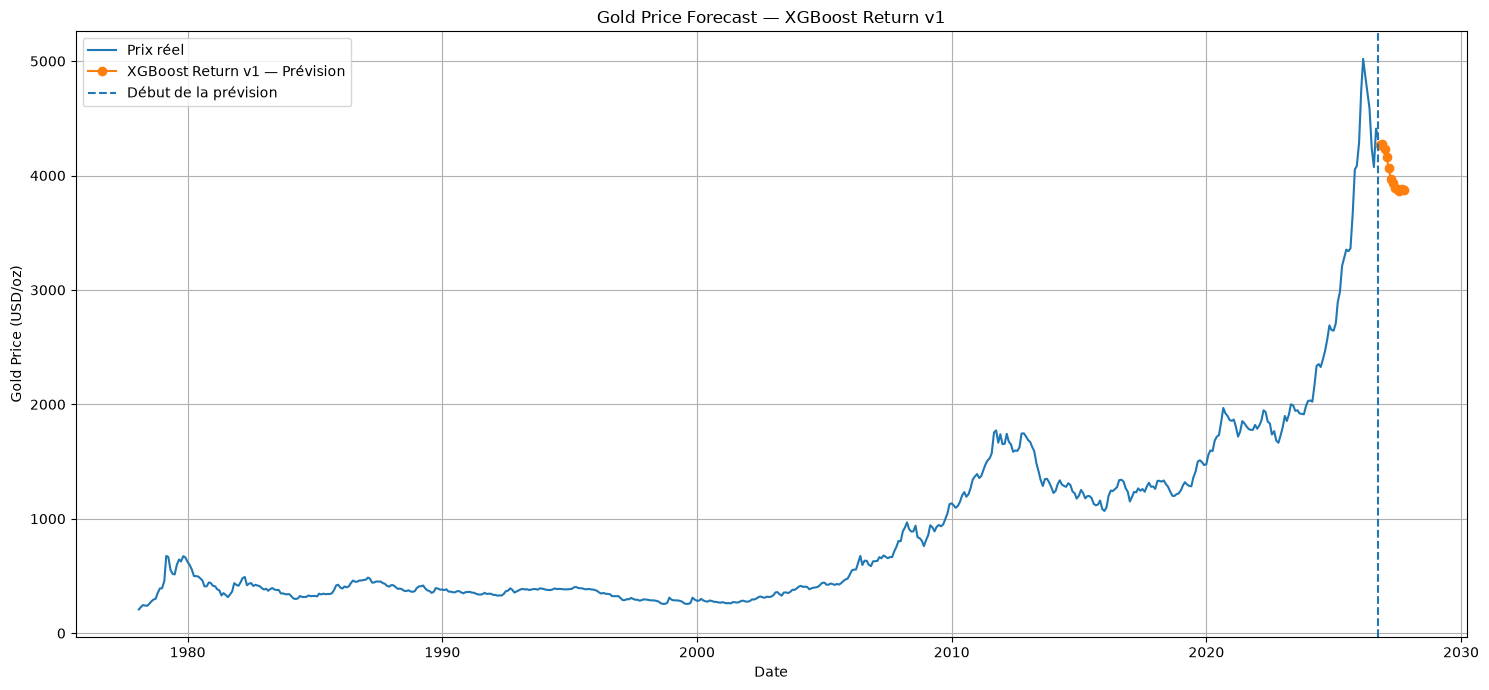

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

# Historique
plt.plot(
    gold["Date"],
    gold["USD"],
    label="Prix réel"
)

# Prévision
plt.plot(
    forecast_2026_2027["Date"],
    forecast_2026_2027["Predicted_USD"],
    marker="o",
    label="XGBoost Return v1 — Prévision"
)

plt.axvline(
    x=pd.Timestamp("2026-09-30"),
    linestyle="--",
    label="Début de la prévision"
)

plt.title("Gold Price Forecast — XGBoost Return v1")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
# Série des rendements
lstm_data = gold[["Date", "USD"]].copy()
lstm_data["return"] = lstm_data["USD"].pct_change()

lstm_data = lstm_data.dropna().reset_index(drop=True)

print(lstm_data.shape)
print(lstm_data.head())

(584, 3)
        Date     USD    return
0 1978-02-28  227.27  0.093538
1 1978-03-31  245.67  0.080961
2 1978-04-28  242.05 -0.014735
3 1978-05-31  239.16 -0.011940
4 1978-06-30  257.62  0.077187


In [22]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [23]:
# Longueur de la séquence
sequence_length = 12

returns = lstm_data["return"].values

X_sequences = []
y_sequences = []
dates_sequences = []

for i in range(sequence_length, len(returns)):
    
    X_sequences.append(
        returns[i-sequence_length:i]
    )
    
    y_sequences.append(
        returns[i]
    )
    
    dates_sequences.append(
        lstm_data["Date"].iloc[i]
    )

X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)
dates_sequences = pd.to_datetime(dates_sequences)

print("X shape :", X_sequences.shape)
print("y shape :", y_sequences.shape)

X shape : (572, 12)
y shape : (572,)


In [24]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [25]:
X_sequences = X_sequences.reshape(
    X_sequences.shape[0],
    X_sequences.shape[1],
    1
)

print("X final shape :", X_sequences.shape)

X final shape : (572, 12, 1)


In [26]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [39]:
# ============================================================
# LSTM — Time Series Cross-Validation
# Gold Price Forecasting
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 1. Préparer les données
# ============================================================

lstm_raw = gold[["Date", "USD"]].copy()

lstm_raw["return"] = lstm_raw["USD"].pct_change()

lstm_raw = lstm_raw.dropna(
    subset=["return"]
).reset_index(drop=True)


returns = lstm_raw["return"].values
prices = lstm_raw["USD"].values
dates = lstm_raw["Date"].values

sequence_length = 12


print("Nombre de returns :", len(returns))
print("Dernière date :", dates[-1])
print("Dernier prix :", prices[-1])


# ============================================================
# 2. Fonction création séquences
# ============================================================

def create_sequences(data, sequence_length=12):

    X = []
    y = []

    for i in range(sequence_length, len(data)):

        X.append(
            data[i-sequence_length:i]
        )

        y.append(
            data[i]
        )

    return np.array(X), np.array(y)


# ============================================================
# 3. Fonction construction LSTM
# ============================================================

def build_lstm(sequence_length=12):

    model = Sequential([
        LSTM(
            32,
            input_shape=(sequence_length, 1)
        ),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model


# ============================================================
# 4. Time Series Cross Validation
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=12
)

results_lstm = []

split5_predictions = None


for split, (train_idx, val_idx) in enumerate(
    tscv.split(returns), 1
):

    print(f"\n===== Split {split} =====")


    # ========================================================
    # TRAIN / VALIDATION
    # ========================================================

    train_returns = returns[train_idx]
    val_returns = returns[val_idx]


    # ========================================================
    # Scaling uniquement sur TRAIN
    # ========================================================

    scaler = StandardScaler()

    scaler.fit(
        train_returns.reshape(-1, 1)
    )

    train_scaled = scaler.transform(
        train_returns.reshape(-1, 1)
    ).ravel()


    # ========================================================
    # Séquences TRAIN uniquement
    # ========================================================

    X_train, y_train = create_sequences(
        train_scaled,
        sequence_length
    )

    X_train = X_train.reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )


    # ========================================================
    # Modèle
    # ========================================================

    tf.keras.utils.set_random_seed(42)

    model = build_lstm(
        sequence_length
    )


    # ========================================================
    # Validation interne au TRAIN
    # ========================================================

    validation_size = 12

    X_fit = X_train[:-validation_size]
    y_fit = y_train[:-validation_size]

    X_internal = X_train[-validation_size:]
    y_internal = y_train[-validation_size:]


    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )


    model.fit(
        X_fit,
        y_fit,
        validation_data=(
            X_internal,
            y_internal
        ),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )


    # ========================================================
    # PRÉVISION RÉCURSIVE
    # ========================================================

    # Les 12 derniers returns réellement connus
    history = list(
        train_returns[-sequence_length:]
    )


    # Prix réel juste avant le début de validation
    current_predicted_price = prices[train_idx[-1]]


    predicted_prices = []


    for i in range(len(val_idx)):

        # ----------------------------------------------------
        # Séquence des 12 derniers returns
        # ----------------------------------------------------

        input_sequence = np.array(history)

        input_scaled = scaler.transform(
            input_sequence.reshape(-1, 1)
        )

        input_scaled = input_scaled.reshape(
            1,
            sequence_length,
            1
        )


        # ----------------------------------------------------
        # Prédiction return
        # ----------------------------------------------------

        pred_scaled = model.predict(
            input_scaled,
            verbose=0
        )[0, 0]


        pred_return = scaler.inverse_transform(
            np.array([[pred_scaled]])
        )[0, 0]


        # ----------------------------------------------------
        # Prix prédit
        # ----------------------------------------------------

        current_predicted_price *= (
            1 + pred_return
        )

        predicted_prices.append(
            current_predicted_price
        )


        # ----------------------------------------------------
        # IMPORTANT :
        # on utilise le return prédit
        # pour le mois suivant
        # ----------------------------------------------------

        history.append(
            pred_return
        )

        history = history[
            -sequence_length:
        ]


    # ========================================================
    # VRAIS PRIX DE VALIDATION
    # ========================================================

    # NE PAS les reconstruire avec les prédictions
    actual_prices = prices[val_idx]


    # ========================================================
    # Métriques
    # ========================================================

    actual_prices = np.array(
        actual_prices
    )

    predicted_prices = np.array(
        predicted_prices
    )


    mae = mean_absolute_error(
        actual_prices,
        predicted_prices
    )


    rmse = np.sqrt(
        mean_squared_error(
            actual_prices,
            predicted_prices
        )
    )


    mape = np.mean(
        np.abs(
            (actual_prices - predicted_prices)
            / actual_prices
        )
    ) * 100


    results_lstm.append({
        "Split": split,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })


    # ========================================================
    # Sauvegarder Split 5
    # ========================================================

    if split == 5:

        split5_predictions = pd.DataFrame({
            "Date": dates[val_idx],
            "Actual": actual_prices,
            "LSTM": predicted_prices
        })


# ============================================================
# 5. Résultats
# ============================================================

results_lstm_df = pd.DataFrame(
    results_lstm
)


print("\n==============================")
print("Résultats LSTM")
print("==============================")

print(
    results_lstm_df.round(2)
)


print("\n==============================")
print("Moyenne")
print("==============================")

print(
    results_lstm_df[
        ["MAE", "RMSE", "MAPE"]
    ].mean().round(2)
)


# ============================================================
# 6. Vérification Split 5
# ============================================================

print("\n==============================")
print("Split 5")
print("==============================")

print(
    split5_predictions.round(2)
)


print("\n==============================")
print("Autour du pic")
print("==============================")

print(
    split5_predictions[
        (split5_predictions["Date"] >= "2026-01-01") &
        (split5_predictions["Date"] <= "2026-04-30")
    ].round(2)
)

Nombre de returns : 584
Dernière date : 2026-09-30T00:00:00.000000000
Dernier prix : 4324.72

===== Split 1 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 2 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 3 =====


...


===== Split 4 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 5 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Résultats LSTM
   Split     MAE    RMSE   MAPE
0      1   65.00   82.00   3.53
1      2  211.39  232.17  10.99
2      3  141.90  181.33   5.99
3      4  192.04  238.31   5.86
4      5  455.79  504.49  10.16

Moyenne
MAE     213.22
RMSE    247.66
MAPE      7.31
dtype: float64

Split 5
         Date   Actual     LSTM
0  2025-10-31  4053.28  3781.41
1  2025-11-28  4082.95  3859.39
2  2025-12-31  4289.48  3958.43
3  2026-01-30  4744.46  4066.66
4  2026-02-27  5019.53  4176.47
5  2026-03-31  4862.17  4286.37
6  2026-04-30  4723.88  4397.45
7  2026-05-29  4587.52  4508.30
8  2026-06-30  4238.32  4621.97
9  2026-07-31  4073.92  4737.28
10 2026-08-31  4409.89  4854.83
11 2026-09-30  4324.72  4973.44

Autour du pic
        Date   Actual     LSTM
3 2026-01-30  4744.46  4066.66
4 2026-02-27  5019.53  4176.47
5 2026-03-31  4862.17  4286.37
6 2026-04-30  4723.88  4397.45


In [28]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [40]:
# ============================================================
# LSTM FINAL
# Gold Price Forecasting
# Toutes les données jusqu'à septembre 2026
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import StandardScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 1. Préparer toutes les données
# ============================================================

final_data = gold[
    ["Date", "USD"]
].copy()

final_data["return"] = (
    final_data["USD"].pct_change()
)

final_data = final_data.dropna(
    subset=["return"]
).reset_index(drop=True)


returns = final_data["return"].values

sequence_length = 12


print("Nombre de returns :", len(returns))
print("Dernière date :", final_data["Date"].iloc[-1])
print("Dernier prix :", final_data["USD"].iloc[-1])


# ============================================================
# 2. Scaling
# ============================================================

scaler_final = StandardScaler()

returns_scaled = scaler_final.fit_transform(
    returns.reshape(-1, 1)
).ravel()


# ============================================================
# 3. Créer les séquences
# ============================================================

X_final = []
y_final = []


for i in range(
    sequence_length,
    len(returns_scaled)
):

    X_final.append(
        returns_scaled[
            i-sequence_length:i
        ]
    )

    y_final.append(
        returns_scaled[i]
    )


X_final = np.array(X_final)
y_final = np.array(y_final)


X_final = X_final.reshape(
    X_final.shape[0],
    X_final.shape[1],
    1
)


print("X shape :", X_final.shape)
print("y shape :", y_final.shape)


# ============================================================
# 4. Construire le LSTM final
# ============================================================

tf.keras.utils.set_random_seed(42)

final_lstm = Sequential([
    LSTM(
        32,
        input_shape=(sequence_length, 1)
    ),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])


final_lstm.compile(
    optimizer="adam",
    loss="mse"
)


# ============================================================
# 5. Early stopping
# ============================================================

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


# ============================================================
# 6. Entraînement
# ============================================================

history_final = final_lstm.fit(
    X_final,
    y_final,
    validation_split=0.10,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Nombre de returns : 584
Dernière date : 2026-09-30 00:00:00
Dernier prix : 4324.72
X shape : (572, 12, 1)
y shape : (572,)
Epoch 1/100


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.9636 - val_loss: 0.7646
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9532 - val_loss: 0.7564
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9506 - val_loss: 0.7511
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9474 - val_loss: 0.7496
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9487 - val_loss: 0.7446
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9482 - val_loss: 0.7446
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9429 - val_loss: 0.7418
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9443 - val_loss: 0.7364
Epoch 9/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9402 - val_loss: 0.7306
Epoch 10/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9361 - val_loss: 0.7331
Epoch 11/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9273 - val_loss: 0.7203
Epoch 12/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9331 - val_l

In [30]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


In [41]:
# ============================================================
# FORECAST FINAL
# Octobre 2026 → Septembre 2027
# ============================================================


# ============================================================
# 1. Dates futures
# ============================================================

future_dates = pd.date_range(
    start="2026-10-31",
    periods=12,
    freq="ME"
)


# ============================================================
# 2. Les 12 derniers returns connus
# ============================================================

history_returns = list(
    returns[-sequence_length:]
)


# ============================================================
# 3. Dernier prix réel
# ============================================================

last_actual_price = gold["USD"].iloc[-1]

current_price = last_actual_price


# ============================================================
# 4. Listes résultats
# ============================================================

predicted_returns = []
predicted_prices = []


# ============================================================
# 5. Prévision récursive
# ============================================================

for date in future_dates:


    # --------------------------------------------------------
    # Séquence des 12 derniers returns
    # --------------------------------------------------------

    input_sequence = np.array(
        history_returns
    )


    input_scaled = scaler_final.transform(
        input_sequence.reshape(-1, 1)
    )


    input_scaled = input_scaled.reshape(
        1,
        sequence_length,
        1
    )


    # --------------------------------------------------------
    # Prédire le prochain return
    # --------------------------------------------------------

    pred_scaled = final_lstm.predict(
        input_scaled,
        verbose=0
    )[0, 0]


    pred_return = scaler_final.inverse_transform(
        np.array([[pred_scaled]])
    )[0, 0]


    # --------------------------------------------------------
    # Reconstruire le prix
    # --------------------------------------------------------

    current_price *= (
        1 + pred_return
    )


    # --------------------------------------------------------
    # Sauvegarder
    # --------------------------------------------------------

    predicted_returns.append(
        pred_return
    )

    predicted_prices.append(
        current_price
    )


    # --------------------------------------------------------
    # IMPORTANT :
    # return prédit devient l'entrée suivante
    # --------------------------------------------------------

    history_returns.append(
        pred_return
    )

    history_returns = history_returns[
        -sequence_length:
    ]


# ============================================================
# 6. DataFrame final
# ============================================================

lstm_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Return": predicted_returns,
    "Predicted_USD": predicted_prices
})


# ============================================================
# 7. Affichage
# ============================================================

print("\n==============================")
print("LSTM Forecast")
print("==============================")

print(
    lstm_forecast.round(2)
)


# ============================================================
# 8. Variation totale prévue
# ============================================================

last_price = gold["USD"].iloc[-1]
final_price = lstm_forecast["Predicted_USD"].iloc[-1]

total_change = (
    (final_price / last_price) - 1
) * 100


print(
    f"\nDernier prix réel : "
    f"{last_price:.2f} USD"
)

print(
    f"Prix prévu Sep 2027 : "
    f"{final_price:.2f} USD"
)

print(
    f"Variation prévue : "
    f"{total_change:.2f}%"
)


LSTM Forecast
         Date  Predicted_Return  Predicted_USD
0  2026-10-31              0.00        4344.94
1  2026-11-30              0.01        4371.58
2  2026-12-31              0.01        4396.00
3  2027-01-31              0.00        4414.35
4  2027-02-28              0.00        4423.36
5  2027-03-31              0.00        4426.07
6  2027-04-30              0.00        4431.27
7  2027-05-31              0.00        4441.75
8  2027-06-30              0.00        4459.55
9  2027-07-31              0.01        4488.91
10 2027-08-31              0.01        4526.48
11 2027-09-30              0.01        4559.35

Dernier prix réel : 4324.72 USD
Prix prévu Sep 2027 : 4559.35 USD
Variation prévue : 5.43%


In [32]:
print(
    gold.loc[
        gold["USD"].idxmax(),
        ["Date", "USD"]
    ]
)

Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object


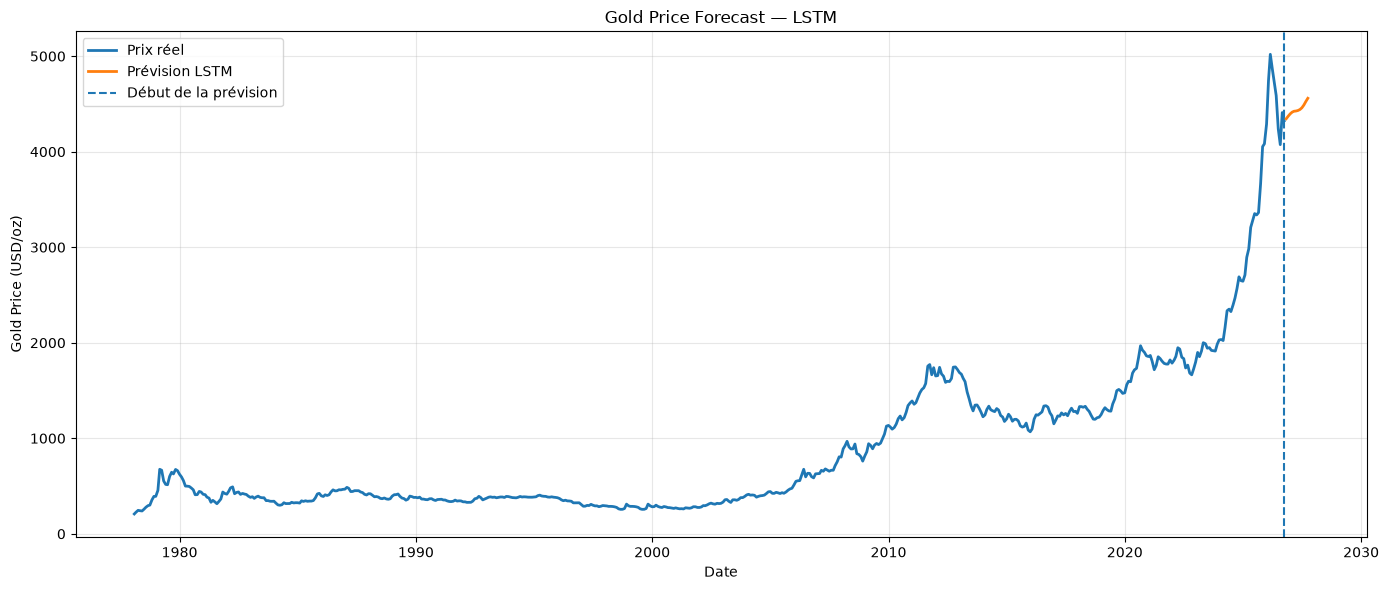

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Historique
plt.plot(
    gold["Date"],
    gold["USD"],
    label="Prix réel",
    linewidth=2
)

# Prévision LSTM
plt.plot(
    lstm_forecast["Date"],
    lstm_forecast["Predicted_USD"],
    label="Prévision LSTM",
    linewidth=2
)

# Point de départ du forecast
plt.axvline(
    x=gold["Date"].iloc[-1],
    linestyle="--",
    label="Début de la prévision"
)

plt.title("Gold Price Forecast — LSTM")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
plt.figure(figsize=(14, 6))

plt.plot(
    split5_lstm["Date"],
    split5_lstm["Actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    split5_lstm["Date"],
    split5_lstm["LSTM"],
    label="LSTM",
    linewidth=2
)

plt.title("LSTM — Split 5 Validation")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'split5_lstm' is not defined

<Figure size 1400x600 with 0 Axes>

In [37]:
# ============================================================
# PRÉVISION RÉCURSIVE — CORRECTE
# ============================================================

history = list(train_returns[-sequence_length:])

# Prix réel juste avant la validation
current_predicted_price = prices[train_idx[-1]]

predicted_prices = []

# Les vrais prix de validation
actual_prices = prices[val_idx]


for i in range(len(val_idx)):

    # --------------------------------------------------------
    # Préparer les 12 derniers returns
    # --------------------------------------------------------

    input_sequence = np.array(history)

    input_scaled = scaler.transform(
        input_sequence.reshape(-1, 1)
    )

    input_scaled = input_scaled.reshape(
        1,
        sequence_length,
        1
    )

    # --------------------------------------------------------
    # Prédire le prochain return
    # --------------------------------------------------------

    pred_scaled = model.predict(
        input_scaled,
        verbose=0
    )[0, 0]

    pred_return = scaler.inverse_transform(
        np.array([[pred_scaled]])
    )[0, 0]

    # --------------------------------------------------------
    # Prix prédit
    # --------------------------------------------------------

    current_predicted_price *= (1 + pred_return)

    predicted_prices.append(
        current_predicted_price
    )

    # --------------------------------------------------------
    # IMPORTANT :
    # utiliser le return PRÉDIT pour le mois suivant
    # --------------------------------------------------------

    history.append(pred_return)

    history = history[-sequence_length:]
split5_corrected = pd.DataFrame({
    "Date": dates[val_idx],
    "Actual": actual_prices,
    "LSTM": predicted_prices
})

print(split5_corrected.round(2))

         Date   Actual     LSTM
0  2025-10-31  4053.28  3789.26
1  2025-11-28  4082.95  3883.28
2  2025-12-31  4289.48  3990.50
3  2026-01-30  4744.46  4114.89
4  2026-02-27  5019.53  4246.97
5  2026-03-31  4862.17  4373.53
6  2026-04-30  4723.88  4502.80
7  2026-05-29  4587.52  4622.54
8  2026-06-30  4238.32  4747.82
9  2026-07-31  4073.92  4880.83
10 2026-08-31  4409.89  5028.12
11 2026-09-30  4324.72  5187.58


GRU

In [43]:
# ============================================================
# GRU — Time Series Cross-Validation
# Gold Price Forecasting
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping


# ============================================================
# 1. Préparer les données
# ============================================================

gru_raw = gold[["Date", "USD"]].copy()

gru_raw["return"] = gru_raw["USD"].pct_change()

gru_raw = gru_raw.dropna(
    subset=["return"]
).reset_index(drop=True)

returns = gru_raw["return"].values
prices = gru_raw["USD"].values
dates = gru_raw["Date"].values

sequence_length = 12


# ============================================================
# 2. Création des séquences
# ============================================================

def create_sequences(data, sequence_length=12):

    X = []
    y = []

    for i in range(sequence_length, len(data)):

        X.append(
            data[i-sequence_length:i]
        )

        y.append(
            data[i]
        )

    return np.array(X), np.array(y)


# ============================================================
# 3. Construction du GRU
# ============================================================

def build_gru(sequence_length=12):

    model = Sequential([
        GRU(
            32,
            input_shape=(sequence_length, 1)
        ),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model


# ============================================================
# 4. Time Series Cross Validation
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=5,
    test_size=12
)

results_gru = []

split5_gru = None


for split, (train_idx, val_idx) in enumerate(
    tscv.split(returns), 1
):

    print(f"\n===== Split {split} =====")


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_returns = returns[train_idx]


    # --------------------------------------------------------
    # Scaling uniquement TRAIN
    # --------------------------------------------------------

    scaler = StandardScaler()

    scaler.fit(
        train_returns.reshape(-1, 1)
    )

    train_scaled = scaler.transform(
        train_returns.reshape(-1, 1)
    ).ravel()


    # --------------------------------------------------------
    # Séquences TRAIN
    # --------------------------------------------------------

    X_train, y_train = create_sequences(
        train_scaled,
        sequence_length
    )

    X_train = X_train.reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )


    # --------------------------------------------------------
    # Modèle
    # --------------------------------------------------------

    tf.keras.utils.set_random_seed(42)

    model = build_gru(
        sequence_length
    )


    # --------------------------------------------------------
    # Validation interne TRAIN
    # --------------------------------------------------------

    validation_size = 12

    X_fit = X_train[:-validation_size]
    y_fit = y_train[:-validation_size]

    X_internal = X_train[-validation_size:]
    y_internal = y_train[-validation_size:]


    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )


    model.fit(
        X_fit,
        y_fit,
        validation_data=(
            X_internal,
            y_internal
        ),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )


    # --------------------------------------------------------
    # Prévision récursive
    # --------------------------------------------------------

    history = list(
        train_returns[-sequence_length:]
    )

    current_predicted_price = prices[
        train_idx[-1]
    ]

    predicted_prices = []


    for i in range(len(val_idx)):

        input_sequence = np.array(history)

        input_scaled = scaler.transform(
            input_sequence.reshape(-1, 1)
        )

        input_scaled = input_scaled.reshape(
            1,
            sequence_length,
            1
        )


        # Prédiction du return
        pred_scaled = model.predict(
            input_scaled,
            verbose=0
        )[0, 0]


        pred_return = scaler.inverse_transform(
            np.array([[pred_scaled]])
        )[0, 0]


        # Prix prédit
        current_predicted_price *= (
            1 + pred_return
        )

        predicted_prices.append(
            current_predicted_price
        )


        # Return prédit pour l'étape suivante
        history.append(
            pred_return
        )

        history = history[
            -sequence_length:
        ]


    # --------------------------------------------------------
    # Vrais prix
    # --------------------------------------------------------

    actual_prices = prices[val_idx]


    # --------------------------------------------------------
    # Métriques
    # --------------------------------------------------------

    mae = mean_absolute_error(
        actual_prices,
        predicted_prices
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_prices,
            predicted_prices
        )
    )

    mape = np.mean(
        np.abs(
            (actual_prices - predicted_prices)
            / actual_prices
        )
    ) * 100


    results_gru.append({
        "Split": split,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    })


    # --------------------------------------------------------
    # Sauvegarder Split 5
    # --------------------------------------------------------

    if split == 5:

        split5_gru = pd.DataFrame({
            "Date": dates[val_idx],
            "Actual": actual_prices,
            "GRU": predicted_prices
        })


# ============================================================
# 5. Résultats
# ============================================================

results_gru_df = pd.DataFrame(
    results_gru
)


print("\n==============================")
print("Résultats GRU")
print("==============================")

print(
    results_gru_df.round(2)
)


print("\n==============================")
print("Moyenne")
print("==============================")

print(
    results_gru_df[
        ["MAE", "RMSE", "MAPE"]
    ].mean().round(2)
)


# ============================================================
# 6. Split 5
# ============================================================

print("\n==============================")
print("GRU — Split 5")
print("==============================")

print(
    split5_gru.round(2)
)


===== Split 1 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 2 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 3 =====


...


===== Split 4 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



===== Split 5 =====


c:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Résultats GRU
   Split     MAE    RMSE   MAPE
0      1   77.39  109.09   4.35
1      2  199.68  219.23  10.38
2      3  221.09  270.48   9.41
3      4  236.77  297.81   7.19
4      5  482.75  588.95  10.43

Moyenne
MAE     243.54
RMSE    297.11
MAPE      8.35
dtype: float64

GRU — Split 5
         Date   Actual      GRU
0  2025-10-31  4053.28  3747.32
1  2025-11-28  4082.95  3782.94
2  2025-12-31  4289.48  3818.12
3  2026-01-30  4744.46  3860.18
4  2026-02-27  5019.53  3906.21
5  2026-03-31  4862.17  3952.93
6  2026-04-30  4723.88  3999.54
7  2026-05-29  4587.52  4045.18
8  2026-06-30  4238.32  4089.93
9  2026-07-31  4073.92  4134.18
10 2026-08-31  4409.89  4178.39
11 2026-09-30  4324.72  4222.73


XGBoost trained on monthly returns with lag, rolling-statistics and calendar features was selected as the final forecasting model based on rolling-origin time-series cross-validation. It achieved the lowest average MAE (196.07 USD) and MAPE (6.55%) among the evaluated models.

entrainment final de XGBOOST

In [54]:
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

# ============================================================
# 1. Préparer les données finales
# ============================================================

gold_return = gold[["Date", "USD"]].copy()

gold_return["return"] = gold_return["USD"].pct_change()

# Lags
gold_return["return_lag_1"] = gold_return["return"].shift(1)
gold_return["return_lag_2"] = gold_return["return"].shift(2)
gold_return["return_lag_3"] = gold_return["return"].shift(3)
gold_return["return_lag_6"] = gold_return["return"].shift(6)
gold_return["return_lag_12"] = gold_return["return"].shift(12)

# Rolling statistics
gold_return["return_mean_3"] = (
    gold_return["return"].shift(1).rolling(3).mean()
)

gold_return["return_mean_6"] = (
    gold_return["return"].shift(1).rolling(6).mean()
)

gold_return["return_mean_12"] = (
    gold_return["return"].shift(1).rolling(12).mean()
)

gold_return["return_std_3"] = (
    gold_return["return"].shift(1).rolling(3).std()
)

gold_return["return_std_6"] = (
    gold_return["return"].shift(1).rolling(6).std()
)

gold_return["return_std_12"] = (
    gold_return["return"].shift(1).rolling(12).std()
)

# Mois
gold_return["month"] = gold_return["Date"].dt.month

# Supprimer les lignes avec NaN
gold_return = gold_return.dropna().reset_index(drop=True)


# ============================================================
# 2. Features / Target
# ============================================================

features = [
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_6",
    "return_lag_12",
    "return_mean_3",
    "return_mean_6",
    "return_mean_12",
    "return_std_3",
    "return_std_6",
    "return_std_12",
    "month"
]

X = gold_return[features]
y = gold_return["return"]

print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 3. Modèle XGBoost final
# ============================================================

final_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

# Entraînement sur toutes les données
final_model.fit(X, y)

print("Modèle XGBoost final entraîné avec succès.")

X shape: (572, 12)
y shape: (572,)
Modèle XGBoost final entraîné avec succès.


In [55]:
import os

os.makedirs("models", exist_ok=True)

final_model.save_model("models/xgboost_gold_return.json")

print("Modèle sauvegardé avec succès.")

Modèle sauvegardé avec succès.


In [56]:
import json

with open("models/features.json", "w") as f:
    json.dump(features, f)

print("Features sauvegardées.")

Features sauvegardées.


In [57]:
os.makedirs("outputs", exist_ok=True)

forecast_df.to_csv(
    "outputs/forecast_2026_2027.csv",
    index=False
)

print("Forecast sauvegardé.")

Forecast sauvegardé.


In [50]:
# ============================================================
# 4. Prévision Octobre 2026 → Septembre 2027
# ============================================================

history_returns = list(gold_return["return"].values)

last_price = gold["USD"].iloc[-1]

future_dates = pd.date_range(
    start="2026-10-31",
    periods=12,
    freq="ME"
)

future_predictions = []

current_price = last_price

for date in future_dates:

    # Construire les features à partir de l'historique disponible
    r = pd.Series(history_returns)

    row = {
        "return_lag_1": r.iloc[-1],
        "return_lag_2": r.iloc[-2],
        "return_lag_3": r.iloc[-3],
        "return_lag_6": r.iloc[-6],
        "return_lag_12": r.iloc[-12],

        "return_mean_3": r.iloc[-3:].mean(),
        "return_mean_6": r.iloc[-6:].mean(),
        "return_mean_12": r.iloc[-12:].mean(),

        "return_std_3": r.iloc[-3:].std(),
        "return_std_6": r.iloc[-6:].std(),
        "return_std_12": r.iloc[-12:].std(),

        "month": date.month
    }

    X_future = pd.DataFrame([row])[features]

    # Prédire le rendement
    predicted_return = final_model.predict(X_future)[0]

    # Reconstruire le prix
    predicted_price = current_price * (1 + predicted_return)

    future_predictions.append({
        "Date": date,
        "Predicted_Return": predicted_return,
        "Predicted_USD": predicted_price
    })

    # Ajouter le rendement prédit à l'historique
    history_returns.append(predicted_return)

    # Le prix prédit devient le prix de départ du mois suivant
    current_price = predicted_price


forecast_df = pd.DataFrame(future_predictions)

print("\n==============================")
print("FORECAST XGBOOST FINAL")
print("==============================")

print(forecast_df)


FORECAST XGBOOST FINAL
         Date  Predicted_Return  Predicted_USD
0  2026-10-31         -0.012619    4270.146794
1  2026-11-30          0.002176    4279.437304
2  2026-12-31         -0.011317    4231.008890
3  2027-01-31         -0.017157    4158.415628
4  2027-02-28         -0.022339    4065.522077
5  2027-03-31         -0.023242    3971.032922
6  2027-04-30         -0.010108    3930.894218
7  2027-05-31         -0.011059    3887.422514
8  2027-06-30         -0.001309    3882.335587
9  2027-07-31         -0.004299    3865.645716
10 2027-08-31          0.003838    3880.483226
11 2027-09-30         -0.002204    3871.931794


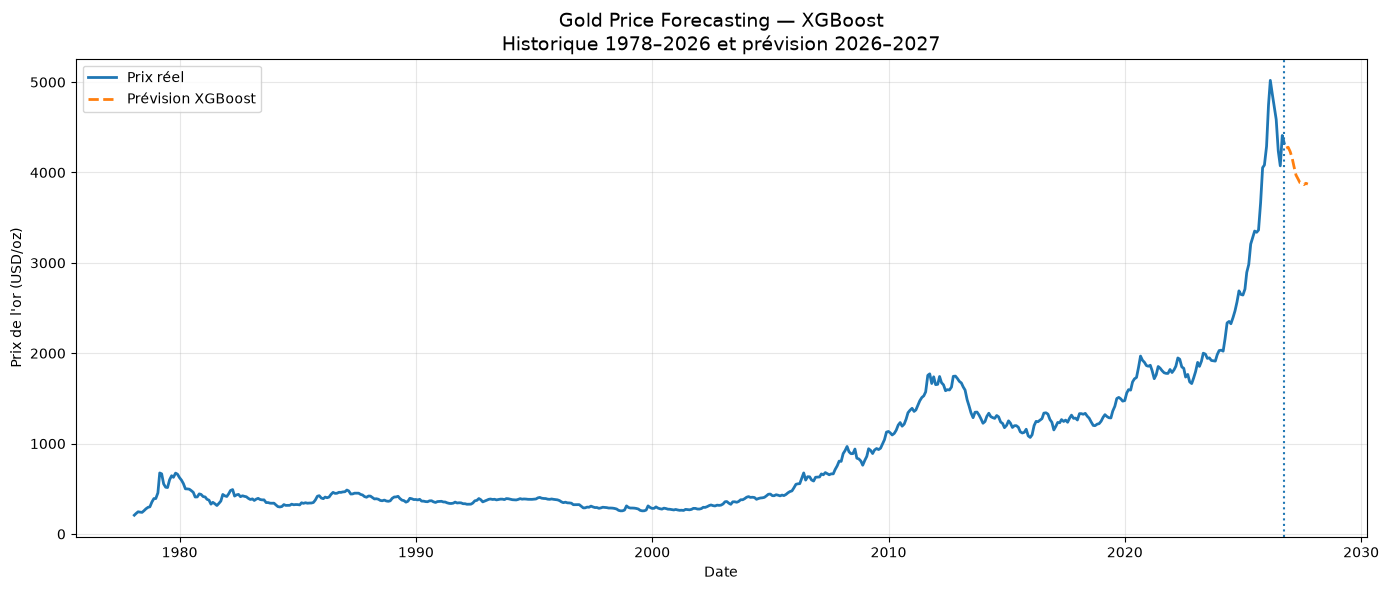

In [51]:
import matplotlib.pyplot as plt

# ============================================================
# Graphique final : Historique + Prévision XGBoost
# ============================================================

plt.figure(figsize=(14, 6))

# Historique
plt.plot(
    gold["Date"],
    gold["USD"],
    label="Prix réel",
    linewidth=2
)

# Prévision
plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_USD"],
    label="Prévision XGBoost",
    linewidth=2,
    linestyle="--"
)

# Ligne verticale séparant historique / forecast
plt.axvline(
    gold["Date"].iloc[-1],
    linestyle=":"
)

plt.title(
    "Gold Price Forecasting — XGBoost\n"
    "Historique 1978–2026 et prévision 2026–2027",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Prix de l'or (USD/oz)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,1,3)",
        "XGBoost Return",
        "LSTM",
        "GRU"
    ],
    "MAE": [
        369.63,
        550.26,
        294.54,
        196.07,
        213.22,
        243.54
    ],
    "RMSE": [
        422.58,
        583.17,
        354.44,
        249.23,
        247.66,
        297.11
    ],
    "MAPE (%)": [
        11.83,
        16.55,
        10.30,
        6.55,
        7.31,
        8.35
    ]
})

comparison

,Model,MAE,RMSE,MAPE (%)
0,Naive,369.63,422.58,11.83
1,Seasonal Naive,550.26,583.17,16.55
2,"ARIMA(2,1,3)",294.54,354.44,10.30
3,XGBoost Return,196.07,249.23,6.55
4,LSTM,213.22,247.66,7.31
5,GRU,243.54,297.11,8.35


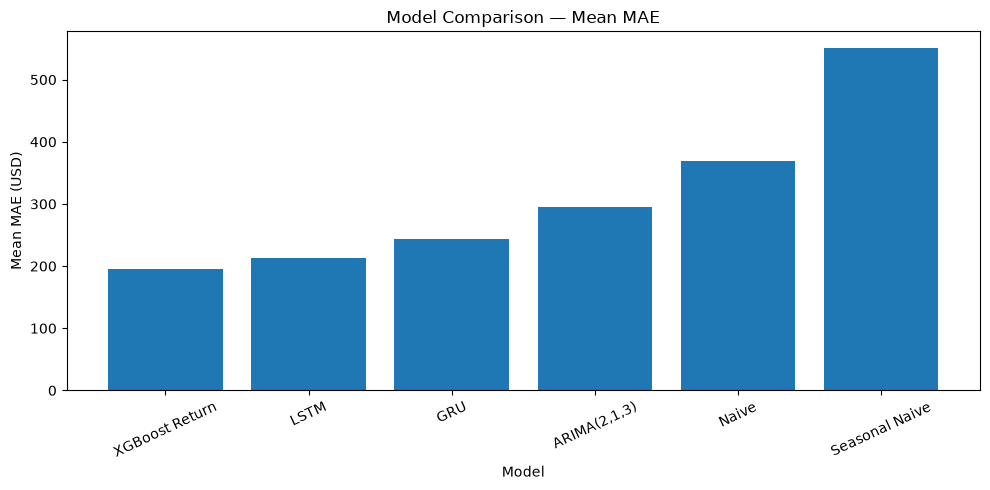

In [53]:
comparison_sorted = comparison.sort_values("MAE")

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_sorted["Model"],
    comparison_sorted["MAE"]
)

plt.ylabel("Mean MAE (USD)")
plt.xlabel("Model")
plt.title("Model Comparison — Mean MAE")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

Model Selection

Several forecasting approaches were evaluated using rolling-origin time-series cross-validation, including Naive and Seasonal Naive baselines, ARIMA, XGBoost, LSTM and GRU.

XGBoost trained on monthly returns achieved the best overall performance, with a mean MAE of 196.07 USD and a mean MAPE of 6.55%. Although LSTM obtained a slightly lower RMSE (247.66 USD vs. 249.23 USD), XGBoost performed better in MAE and MAPE and provided a more stable overall performance.

Therefore, XGBoost Return was selected as the final forecasting model.

Final Forecast

The final XGBoost model was retrained using the complete historical dataset available through September 2026. It was then used to recursively forecast the monthly gold price from October 2026 to September 2027.

The forecast indicates a gradual decline from approximately 4,270 USD/oz in October 2026 to around 3,872 USD/oz in September 2027, corresponding to an approximate decline of 10.5% over the forecast horizon.

This forecast should be interpreted as a statistical projection based solely on historical gold-price dynamics and engineered time-series features. It should not be considered a certain prediction of future market prices.

In [58]:
from xgboost import XGBRegressor

loaded_model = XGBRegressor()

loaded_model.load_model(
    "models/xgboost_gold_return.json"
)

print("Modèle chargé avec succès.")

Modèle chargé avec succès.


In [59]:
original_pred = final_model.predict(X)
loaded_pred = loaded_model.predict(X)

difference = abs(original_pred - loaded_pred).max()

print("Différence maximale :", difference)

Différence maximale : 0.0


In [60]:
forecast_check = pd.read_csv(
    "outputs/forecast_2026_2027.csv"
)

forecast_check["Date"] = pd.to_datetime(
    forecast_check["Date"]
)

print(forecast_check)

         Date  Predicted_Return  Predicted_USD
0  2026-10-31         -0.012619    4270.146794
1  2026-11-30          0.002176    4279.437304
2  2026-12-31         -0.011317    4231.008890
3  2027-01-31         -0.017157    4158.415628
4  2027-02-28         -0.022339    4065.522077
5  2027-03-31         -0.023242    3971.032922
6  2027-04-30         -0.010108    3930.894218
7  2027-05-31         -0.011059    3887.422514
8  2027-06-30         -0.001309    3882.335587
9  2027-07-31         -0.004299    3865.645716
10 2027-08-31          0.003838    3880.483226
11 2027-09-30         -0.002204    3871.931794


In [61]:
import os

os.makedirs("outputs", exist_ok=True)

comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("model_comparison.csv sauvegardé.")

model_comparison.csv sauvegardé.


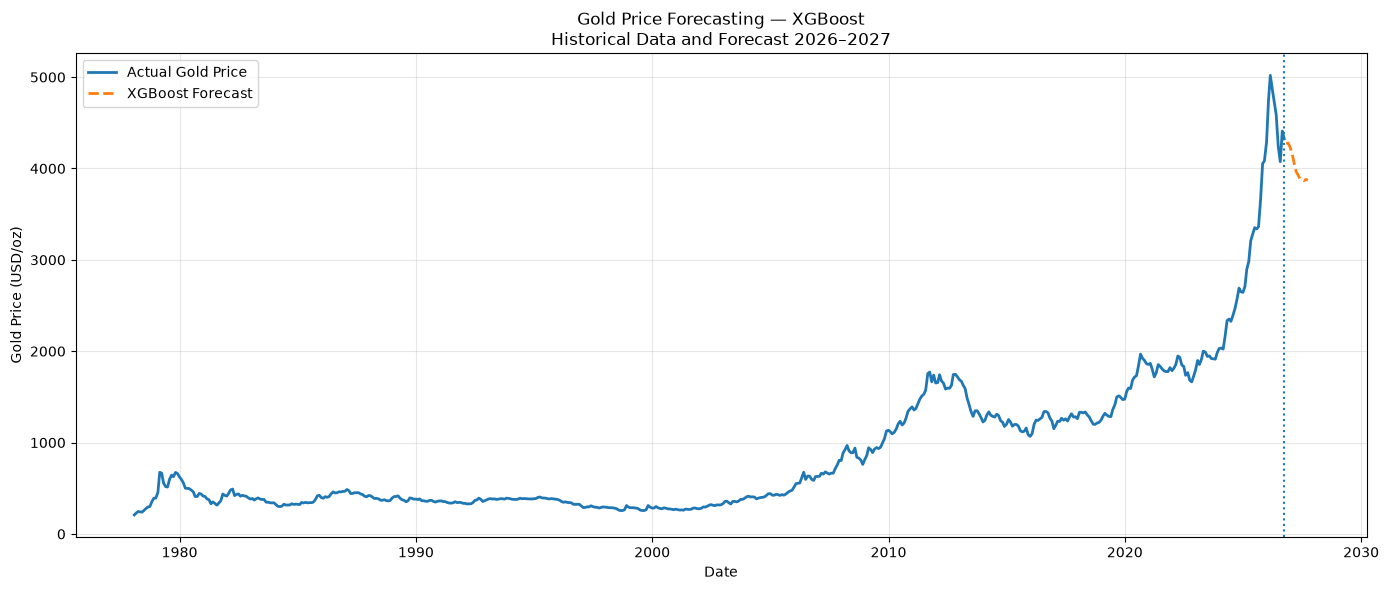

final_forecast.png sauvegardé.


In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    gold["Date"],
    gold["USD"],
    label="Actual Gold Price",
    linewidth=2
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_USD"],
    label="XGBoost Forecast",
    linewidth=2,
    linestyle="--"
)

plt.axvline(
    gold["Date"].iloc[-1],
    linestyle=":"
)

plt.title(
    "Gold Price Forecasting — XGBoost\n"
    "Historical Data and Forecast 2026–2027"
)

plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "outputs/final_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("final_forecast.png sauvegardé.")